<p style="font-size:11px;"><em><strong>Créditos</strong>: El contenido de este cuaderno ha sido tomado de varias fuentes, pero especialmente de <a href="https://scikit-learn.org/stable/auto_examples/gaussian_process/plot_gpr_noisy_targets.html#sphx-glr-auto-examples-gaussian-process-plot-gpr-noisy-targets-py">scikit-learn1</a>, <a href="https://scikit-learn.org/stable/auto_examples/gaussian_process/plot_compare_gpr_krr.html#sphx-glr-auto-examples-gaussian-process-plot-compare-gpr-krr-py">sciki-learn2</a>, <a href="https://domino.ai/blog/fitting-gaussian-process-models-python">Chris Fonnesbeck</a>, <a href="https://github.com/jwangjie/Gaussian-Process-Regression-Tutorial/blob/master/gpr_tutorial.ipynb">Jie Wang, Offroad Robotics, Queen's University</a>, <a href="https://nbviewer.org/github/adamian/adamian.github.io/blob/master/talks/Brown2016.ipynb">Andreas Damianou - Brown University</a>. El compilador se disculpa por cualquier omisión involuntaria y estaría encantado de agregar un reconocimiento.</em></p>

# Procesos Gaussianos con Python

## Objetivos de aprendizaje

Al finalizar este notebook, el estudiante será capaz de:

- Comprender los Procesos Gaussianos (GP) como distribuciones de probabilidad sobre funciones.
- Derivar e implementar desde cero la inferencia posterior de un GP con NumPy y SciPy.
- Entender el rol del kernel (función de covarianza) en la definición de la estructura espacial del GP.
- Incorporar observaciones ruidosas al modelo GP y analizar el efecto del nivel de ruido en las predicciones.
- Relacionar los Procesos Gaussianos con el Kriging geoestadístico como caso especial.

**Requisitos previos:** `14_Kriging` — Kriging y variogramas; álgebra lineal (matrices de covarianza, descomposición de Cholesky); cálculo multivariado.

Los Procesos Gaussianos (GP) es una técnica de regresión no paramétrica poderosa y flexible utilizada en aprendizaje automático y estadística. Es particularmente útil cuando se trata de problemas que involucran datos continuos, donde la relación entre las variables de entrada y la salida no se conoce explícitamente o puede ser compleja. La GP es un enfoque Bayesiano que puede modelar la certeza en las predicciones, lo que la convierte en una herramienta valiosa para diversas aplicaciones.

Los GP se basan en el concepto de un proceso Gaussiano, que es una colección de variables aleatorias, cualquiera de las cuales en un número finito tiene una distribución Gaussiana conjunta. Un proceso Gaussiano se puede pensar como una distribución de funciones. A continuación se presentan algunas de sus características principales:

**1. Naturaleza No Paramétrica:** A diferencia de otros modelos que requieren un número fijo de parámetros, los GPs pueden adaptarse a la complejidad de los datos. Esto los hace versátiles para modelar relaciones no lineales y complejas entre las variables de entrada y salida.

**2. Predicciones Probabilísticas:** Los GPs no solo proporcionan un valor puntual de predicción, sino que también generan una distribución de probabilidad para dicho valor. Esto permite cuantificar la incertidumbre asociada a las predicciones, siendo una información muy valiosa en muchos escenarios.

**3. Interpolación y Suavizado:** Los GPs son particularmente útiles para trabajar con datos ruidosos o muestreados de forma irregular. Gracias a su capacidad de suavizar el ruido y predecir valores intermedios entre los datos observados, se convierten en una herramienta adecuada para este tipo de problemas.

**4. Marginalización de Hiperparámetros:** En lugar de necesitar un ajuste manual de los hiperparámetros del modelo (parámetros que controlan su comportamiento general), los GPs los marginalizan. Esto significa que integran sobre todos los valores posibles de los hiperparámetros, simplificando el proceso de ajuste del modelo.

Existen diferentes páginas web donde se describen visualmente los GP. Estas son algunas de ellas:

* [A Visual Exploration of Gaussian Processes](https://distill.pub/2019/visual-exploration-gaussian-processes/)
* [Interactive Gaussian Process Visualization](https://www.infinitecuriosity.org/vizgp/)
* [Gaussian Process, not quite for dummies](https://yugeten.github.io/posts/2019/09/GP/)

### Intuición: el Proceso Gaussiano como una distribución sobre funciones

En la regresión clásica (lineal, Random Forest, redes neuronales) organizamos los datos en un dataframe: filas = observaciones, columnas = variables predictoras. El objetivo es encontrar una **fórmula única y fija** (p. ej. $y = w_1 X_1 + w_2 X_2 + b$) que, una vez ajustada, se puede usar prescindiendo del dataset original.

Un Proceso Gaussiano cambia radicalmente esa perspectiva. En estadística básica, una distribución de probabilidad (como la campana de Gauss) es un "saco de números": al extraer un elemento obtienes un escalar. Un **Proceso Gaussiano es un saco de funciones enteras**: al "meter la mano" en él, extraes una curva continua completa.

* **A priori:** el saco contiene todas las curvas posibles del universo (lisas, rugosas, crecientes, decrecientes), cada una con una probabilidad de ser extraída.
* **A posteriori:** al introducir datos conocidos (p. ej. "en $x=2$, $y=5$"), el GP se **condiciona**: todas las curvas del saco que no pasan por esos puntos pierden su probabilidad y se descartan. La predicción final no es una única línea rígida, sino el **promedio de todas las curvas supervivientes**, y la incertidumbre refleja qué tan dispersas están esas curvas en las zonas sin datos.

#### El giro fundamental: covarianza entre observaciones, no entre variables

En los modelos paramétricos clásicos, la covarianza se calcula **entre columnas** (cómo covarían las variables predictoras entre sí). En un GP, la covarianza se calcula **entre filas**, es decir, entre las coordenadas de entrada de cada observación.

Esto tiene una lectura geométrica poderosa: si las variables predictoras $X$ no son atributos abstractos sino **coordenadas de posición** en un mapa (1D si es tiempo, 2D si es latitud/longitud, $N$-D si son variables numéricas), cada dato de entrenamiento es un "alfiler" clavado en ese mapa a una altura $y$. Al predecir en un punto nuevo, el modelo no calcula el peso de una variable: evalúa la geometría espacial completa — "¿a qué distancia estoy de los alfileres que ya conozco?". El problema de ajustar coeficientes se transforma en un problema de **interpolación/extrapolación en un espacio continuo**, exactamente la misma lógica que usa el Kriging (ver [Conexión entre Procesos Gaussianos y Kriging](#Conexión-entre-Procesos-Gaussianos-y-Kriging) más adelante).

## Distribución Gaussiana

Una variable aleatoria $X$ se dice que está distribuida normalmente con media $\mu$ y varianza $\sigma^2$ si su función de densidad de probabilidad (PDF) es:
 
$$ P_X(x) = \frac{1}{\sqrt{2 \pi} \sigma} \exp{\left(-\frac{{\left(x - \mu \right)}^{2}}{2 \sigma^{2}}\right)}$$

La distribución Gaussiana o Normal de $X$ se suele representar por $ P(x) ~ \sim\mathcal{N}(\mu, \sigma^2)$.

Vamos a crear un vector gaussiano con un número de $m$ puntos:

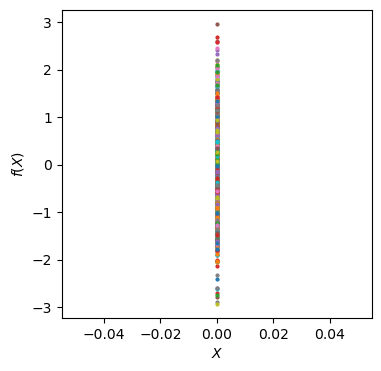

In [1]:
import matplotlib.pyplot as plt
import numpy as np

n = 1         # n gaussianas 1D independientes
m= 1000       # m puntos en una gaussiana 1D
f_random = np.random.normal(size=(n, m))

X = np.linspace(0, 1, n).reshape(-1,1)   # n puntos en el rango (0, 1)

plt.figure(figsize=(4, 4))
plt.plot(X, f_random, 'o', linewidth=1, markersize=1, markeredgewidth=2)
plt.xlabel('$X$')
plt.ylabel('$f(X)$')
plt.show()

Vamos a crear ahora dos vectores gaussianos, cada uno con $m$ puntos. Por ejemplo, colocar el vector $X_1$ en $X = 0$ y otro vector $X_2$ en $X = 1$.

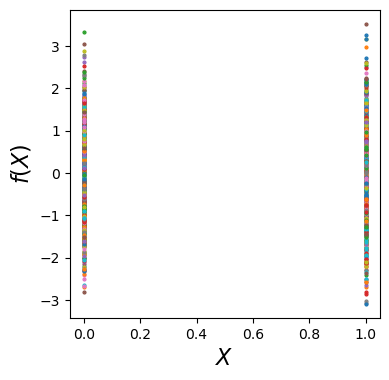

In [2]:
n = 2          # en este caso n funciones Gaussianas
m = 1000       # cada una de m puntos
f_random = np.random.normal(size=(n, m))

X = np.linspace(0, 1, n).reshape(-1,1)   # n puntos de prueba en el rango (0, 1)

plt.figure(figsize=(4, 4))
plt.plot(X, f_random, 'o', linewidth=1, markersize=1, markeredgewidth=2)
plt.xlabel(r'$X$', fontsize = 16)
plt.ylabel(r'$f(X)$', fontsize = 16)
plt.show()

Ten en cuenta que tanto el vector $X_1$ como el vector $X_2$ son Gaussianos.

<img src="https://github.com/jwangjie/Gaussian-Process-Regression-Tutorial/blob/master/img/2gaussian.png?raw=1" width="500"/> 

Ahora creamos funciones lineales que conecten estos puntos. En este caso solo mostraremos 10 puntos y sus funciones lineales.

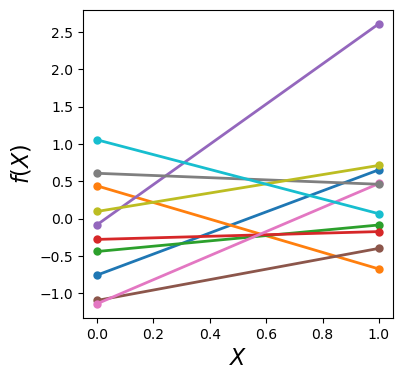

In [3]:
n = 2          
m = 10
f_random = np.random.normal(size=(n, m))

Xshow = np.linspace(0, 1, n).reshape(-1,1)

plt.figure(figsize=(4, 4))
plt.plot(Xshow, f_random, '-o', linewidth=2, markersize=4, markeredgewidth=2)
plt.xlabel(r'$X$', fontsize = 16)
plt.ylabel(r'$f(X)$', fontsize = 16);

Estas líneas se parecen a **funciones** para cada par de puntos. Por otro lado, la gráfica también parece como si estuviéramos muestreando la región $[0, 1]$ con 10 funciones lineales, aunque solo haya dos puntos en cada línea. Desde la perspectiva del muestreo, el dominio $[0, 1]$ es nuestra región de interés, es decir, la región específica en la que realizamos nuestra regresión. 

Podemos ahora generar más variables Gaussianas independientes y conectamos los puntos en orden mediante líneas. Cada función lineal es una observación evaluada en cada variable.

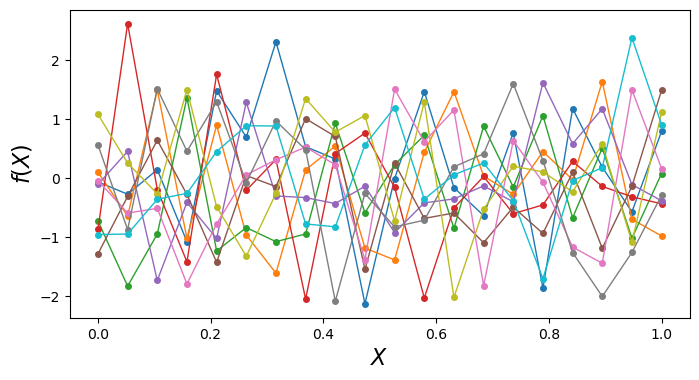

In [4]:
n = 20          
m = 10
f_random = np.random.normal(size=(n, m))

Xshow = np.linspace(0, 1, n).reshape(-1,1)   # n puntos de prueba en el rango (0, 1)

plt.figure(figsize=(8, 4))
plt.plot(Xshow, f_random, '-o', linewidth=1, markersize=3, markeredgewidth=2)
plt.xlabel(r'$X$', fontsize = 16)
plt.ylabel(r'$f(X)$', fontsize = 16)
plt.show()

¿Qué estamos intentando hacer al conectar puntos de variables Gaussianas independientes generados aleatoriamente? 

Cada línea que ven es una función generada al azar. El problema es que, como cada punto es una variable Gaussiana independiente, el valor en un punto $X$ no tiene ninguna relación con el valor en el punto de al lado. Por eso las funciones se ven tan erráticas y ruidosas. No tienen estructura ni suavidad.

Un GP útil no solo dice que cada punto viene de una distribución Gaussiana, sino que define cómo se correlacionan esos puntos entre sí. Es esa correlación la que introduce la 'suavidad' y nos permite conectar los puntos de una manera que se parece a un fenómeno físico real, permitiéndonos interpolar y hacer predicciones con sentido.

Por lo tanto, las funciones obtenidas al conectar Gaussianas independientes no son adecuadas para la regresión; necesitamos Gaussianas que estén correlacionadas entre sí. ¿Cómo describimos una distribución Gaussiana conjunta? Mediante una **Gaussiana multivariable**.

### Distribución conjunta

En algunas situaciones, un sistema (conjunto de datos) debe describirse mediante más de una variable característica $[x_1, x_2, \ldots, x_n]$, y estas variables están correlacionadas entre sí. Si queremos modelar los datos como una Gaussiana de una sola vez, necesitamos una Gaussiana multivariada. Aquí hay ejemplos de la Gaussiana en 2D. 

La Gaussiana en 2D se puede visualizar como una curva en forma de campana tridimensional, donde las alturas representan la densidad de probabilidad. La función $P(x_1, x_2)$ es la [distribución conjunta de probabilidad](https://es.wikipedia.org/wiki/Distribuci%C3%B3n_conjunta_de_probabilidad#Funci%C3%B3n_de_densidad_o_de_masa).

<div id="image-table">
    <table>
	    <tr>
    	    <td style="padding:10px">
        	    <img src="https://github.com/jwangjie/Gaussian-Process-Regression-Tutorial/blob/master/img/2d_gaussian3D_0.8.png?raw=1" width="400"/>
      	    </td>
            <td style="padding:10px">
            	<img src="https://github.com/jwangjie/Gaussian-Process-Regression-Tutorial/blob/master/img/2d_gaussian_0.8.png?raw=1" width="380"/>
            </td>
        </tr>
    </table>
</div> 

Formalmente, la Gaussiana multivariada se expresa como:

$$
f(\vec{x}; \vec{\mu}, \Sigma) = \frac{1}{\sqrt{(2\pi)^d \det(\boldsymbol\Sigma)}} \exp\left(-\tfrac12(\vec{x} - \vec{\mu})^T \Sigma^{-1} (\vec{x} - \vec{\mu})\right)
$$

Donde $\Sigma^{-1}$ es la matriz de covarianza y $d$ es el número de vectores o dimensiones. Para el caso 2D, el vector de medias $\mu$ es un vector $(\mu_1, \mu_2)$, que son las medias independientes de cada variable $x_1$ y $x_2$, por lo que $(\vec{x} - \vec{\mu})$ es igual a:

$$
\begin{pmatrix} x_1 - \mu_1 \\ x_2 - \mu_2 \end{pmatrix}
$$

Y $(\vec{x} - \vec{\mu})^T$ es igual a:

$$
\begin{pmatrix} x_1 - \mu_1 & x_2 - \mu_2 \end{pmatrix}
$$

Por lo tanto:

$$
\begin{pmatrix} x_1 - \mu_1 & x_2 - \mu_2 \end{pmatrix} \Sigma^{-1} \begin{pmatrix} x_1 - \mu_1 \\ x_2 - \mu_2 \end{pmatrix}
$$


La matriz de covarianza de la Gaussiana en 2D es:

$$\begin{pmatrix} \sigma^2_1 & \sigma_{12} \\ \sigma_{21} & \sigma^2_2 \end{pmatrix}$$

Los términos diagonales de la matriz de covarianza son las varianzas independientes de cada variable, $x_1$ y $x_2$. Los términos fuera de la diagonal representan las correlaciones entre las dos variables. Un componente de correlación indica cuánto está relacionada una variable con otra.

Una Gaussiana en 2D se puede expresar como:

$$ \begin{pmatrix} x_1 \\ x_2 \end{pmatrix} \sim \mathcal{N}\left(\begin{pmatrix} \mu1 \\ \mu_2 \end{pmatrix}, \begin{pmatrix} \sigma^2_1 & \sigma_{12} \\ \sigma_{21} & \sigma^2_2 \end{pmatrix}\right) \sim \mathcal{N}(\mu, \Sigma)$$

Cuando tenemos una Gaussiana en $N$ dimensiones, la matriz de covarianza $\Sigma$ es de $N×N$ y su elemento $(i,j)$ es $\Sigma_{ij}=cov(y_i,y_j)$. La matriz $\Sigma$ es simétrica y almacena las covarianzas por pares de todas las variables aleatorias modeladas conjuntamente.

### Distribución marginal

La distribución marginal responde a la pregunta: "Si tengo un modelo conjunto de varias variables, ¿cuál es la distribución de una sola de ellas, ignorando por completo la información de las demás?". La distribución marginal de una variable es simplemente la sombra que esa distribución conjunta proyecta sobre el eje de otra variable. Matemáticamente, para obtener la distribución marginal de una variable (por ejemplo, $x_1$), "sumamos" (integramos) las probabilidades sobre todos los valores posibles de la otra variable ($x_2$).

La propiedad fundamental de la distribución Gaussiana multivariada es que sus distribuciones marginales son también Gaussianas. 

Si partimos de una distribución conjunta para el vector $\vec{x}=\begin{pmatrix}x_1,x_2\end{pmatrix}$ con los siguientes parámetros:

$$
\vec{\mu} = \begin{pmatrix} \mu_1 \\ \mu_2 \end{pmatrix}
$$

$$
\Sigma = \begin{pmatrix}
\sigma^2_1 & \sigma_{12} \\
\sigma_{21} & \sigma^2_2
\end{pmatrix}
$$

Para encontrar la distribución marginal de $X_1$, $p(x_1)$, integramos la distribución conjunta sobre todos los valores de $x_2$:

$$
p(x_1) = \int_{-\infty}^{\infty} f(x_1, x_2) \, dx_2
$$

El resultado de esta integral es una nueva distribución Gaussiana 1D con $\mu_1$ y $\sigma^2_1$. Simplemente tomamos los valores correspondientes a $x_1$ del vector de medias y de la diagonal de la matriz de covarianza. La ecuación para la distribución marginal de $X_1$ es:

$$
p(x_1) = \frac{1}{\sqrt{2\pi\sigma_1^2}} \exp\left(-\frac{(x_1 - \mu_1)^2}{2\sigma_1^2}\right)
$$

### Distribución condicionada

La distribución condicional responde a la pregunta: "Sabiendo que una de las variables ha tomado un valor específico, ¿cuál es la nueva distribución de la otra variable?". Esta es la idea de actualizar nuestra creencia a la luz de nueva evidencia. Ya no estamos viendo la sombra (marginal), sino que estamos tomando un corte transversal o una rebanada de la distribución conjunta en el valor que conocemos.

La propiedad fundamental es, una vez más, que la distribución condicional de una Gaussiana multivariada es también siempre una Gaussiana. Sin embargo, a diferencia de la marginal, sus parámetros (media y varianza) cambian de una manera muy interesante. 

Partimos de la misma distribución conjunta para $\vec{x}=\begin{pmatrix}x_1,x_2\end{pmatrix}$ con su vector de medias $\vec\mu$ y su matriz de covarianza $\Sigma$. Supongamos que observamos que la variable $X_2$ tiene un valor específico, digamos $x_2=a$. Queremos encontrar la nueva distribución para $X_1$, que escribimos como $p(x_1∣x_2=a)$. Esta nueva distribución será una Gaussiana 1D, por lo que necesitamos encontrar su nueva media, $\mu_1∣2$, y su nueva varianza, $\sigma^2 _1∣2$. 

**La Nueva Media Condicional $(\mu_1∣2)$**: La media original de $x_1 (\mu_1)$ se ajusta en función de la información que nos da $x_2=a$. El ajuste depende de qué tan lejos está a de su propia media $(\mu_2)$ y de qué tan fuerte es la correlación.

$$
\mu_{1|2} = \mu_1 + \frac{\sigma_{12}}{\sigma_2} (a - \mu_2)
$$

**La Nueva Varianza Condicional $(\sigma^2 _1∣2)$**: La varianza original de $x_1 (\sigma^2_1)$ se reduce. Como ahora tenemos información, nuestra incertidumbre sobre $x_1$ disminuye. La cantidad de reducción depende de la fuerza de la correlación.

$$
\sigma^2_{1|2} = \sigma_1^2 - \frac{\sigma_{12}^2}{\sigma_2}
$$

Esta expresión es equivalente a $\sigma_1^2 (1−\rho^2)$, lo que muestra claramente que si la correlación $\rho$ es alta, la varianza se reduce mucho. Con estos nuevos parámetros, la ecuación para la distribución condicional $p(x_1∣x_2=a)$ es:

$$
p(x_1 | x_2 = a) = \frac{1}{\sqrt{2\pi\sigma^2_{1|2}}} \exp\left(-\frac{(x_1 - \mu_{1|2})^2}{2\sigma^2_{1|2}}\right)
$$

![Distribución Marginal](distribucion_marginal.png)\n

#### Ejemplo

Sea

$
 \mathbf{Z}=\begin{bmatrix}X\\Y\end{bmatrix}\sim \mathcal N_2\Bigl(\begin{bmatrix}1\\2\end{bmatrix},\begin{bmatrix}4 & 2\\2 & 3\end{bmatrix}\Bigr).
$

**Conjunta**

$
 f_{X,Y}(x,y)=\frac{1}{2\pi\sqrt{\det\boldsymbol\Sigma}}\exp\Bigl\{-\tfrac12[(x-1,\,y-2)\boldsymbol\Sigma^{-1}(x-1,\,y-2)^\top]\Bigr\}.
$

**Marginales**

$
 X\sim\mathcal N(1,4),\qquad Y\sim\mathcal N(2,3).
$

**Condicional de $(Y\mid X=x)$**

$
 Y\mid X=x\;\sim\;\mathcal N\bigl(2+\frac{2}{4}(x-1),\,3-\frac{2^2}{4}\bigr).
$

Si $(X=5$), entonces $(Y\mid X=5\sim\mathcal N(4,2))$.

### Matriz de convarianza (Kernel)

Luego de revisar estos conceptos de la distribución Gaussiana multivariada, retomemos. Volvamos a trazar 20 Gaussianas independientes conectando los puntos en orden mediante líneas. Pero en lugar de generar 20 Gaussianas independientes como antes, realizamos el gráfico de 20 Gaussianas con una matriz de covarianza identidad (media = 0, varianza = 1 y covarianza = 0), esto significa que son también independientes. El cambio está en que en lugar de generar 20 vectores independientes, estamos generando 20 vectores Gaussianos unitarios, es decir media = 0 y varianza = 1.

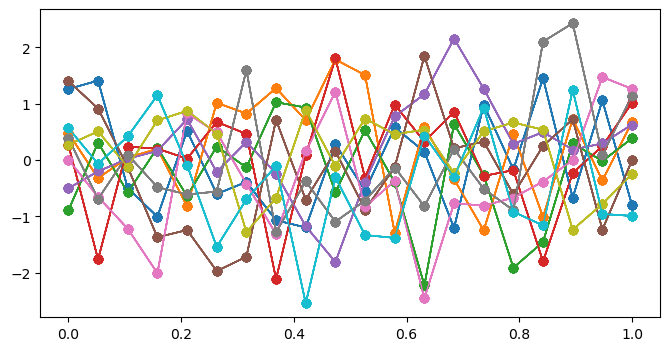

In [5]:
n = 20 
m = 10
mean = np.zeros(n)
cov = np.eye(n)

f_prior = np.random.multivariate_normal(mean, cov, m).T

plt.figure(figsize=(8, 4))
X = np.linspace(0, 1, n).reshape(-1,1)
for i in range(m):
    plt.plot(X, f_prior, '-o', linewidth=1)

Obtuvimos exactamente el mismo gráfico como se esperaba. Ahora, kernelicemos nuestras funciones utilizando la RBF como nuestra covarianza. Si usas una matriz de covarianza con ceros fuera de la diagonal (covarianza cero), obtienes funciones "ruidosas" y sin estructura, porque cada punto es independiente del resto.

Para suavizar y correlacionar las funciones de muestreo utilizamos la matriz de covarianza. Considerando el hecho de que cuando dos vectores son similares, el valor de salida de su producto punto es alto. Si son perpendiculares, es cero. 

En nuestro caso, no nos interesa tanto el "espacio de características". Lo que nos interesa es la idea de reemplazar una operación simple (el producto punto) por una función de similitud más general y potente, a la que llamamos función núcleo o kernel, denotada como $k(x_i,x_j)$. Un kernel es simplemente una función que toma dos puntos, $x_i$ y $x_j$, y devuelve un número que representa su covarianza. Una función de covarianza popular (también conocida como función núcleo) es el kernel exponencial cuadrado, también llamado kernel de función de base radial (RBF) o kernel gaussiano, definido como:

$$
cov(x_i, x_j) = k(x_i, x_j) = \exp\left(-~\frac{(x_i-x_j)^2}{2}\right)
$$

El término $(x_i−x_j)$  es la distancia euclidiana al cuadrado entre los dos puntos. Es una medida de cuán diferentes o lejanos son. La función exponencial de un número negativo, 
exp(−z), tiene una propiedad clave: Si z es pequeño (los puntos están cerca), exp(−z) es cercano a 1. Si z es grande (los puntos están lejos), exp(−z) es cercano a 0. Por lo tanto, si $x_i$ y $x_j$ son muy cercanos: La distancia $(x_i−x_j)$ es casi 0. La covarianza será $exp(0)=1$. ¡Máxima correlación!. Si $x_i$ y $x_j$ están muy lejos: La distancia es grande. La covarianza será un número grande, que es casi 0. ¡Independencia!

### ¿Por qué un kernel y no la covarianza empírica directamente?

Una pregunta natural es: si lo que necesitamos es una matriz de covarianza, ¿por qué no calcularla empíricamente a partir de los datos conocidos, como en estadística descriptiva básica? Hay cuatro razones de peso:

1. **No hay observaciones repetidas del mismo punto.** La covarianza empírica clásica (p. ej. entre "edad" e "ingresos") requiere muchas muestras midiendo ambas variables. En regresión espacial solo tenemos **una** medición por ubicación — no hay "experimentos repetidos" en la misma coordenada para promediar. El kernel resuelve esto asumiendo que la covarianza está dictada por una regla de distancia/similitud entre las variables de entrada.

2. **Necesitamos predecir donde no hay datos.** Una matriz calculada solo con los puntos de entrenamiento es finita ($n \times n$). Pero el objetivo del GP es predecir en puntos nuevos $\mathbf{x}_*$ nunca observados. Como el kernel es una función matemática continua, basta con evaluarla en cualquier par de coordenadas (conocidas o nuevas) para obtener su covarianza teórica al instante: es el puente algebraico que extiende una matriz pequeña hacia cualquier punto del mapa.

3. **El kernel codifica las "leyes físicas" de la función.** Elegir un kernel no es solo rellenar números: es inyectar conocimiento previo sobre cómo se comporta el fenómeno (suave, rugoso, periódico, lineal). La covarianza empírica no permite esta flexibilidad.

4. **Garantiza una matriz definida positiva.** Para que $\Sigma$ sea una matriz de covarianza válida en una Gaussiana multivariada debe ser simétrica y definida positiva. Estimar covarianzas de forma libre entre infinitos puntos destruiría fácilmente esta propiedad; los kernels válidos garantizan matemáticamente que, sin importar qué puntos se elijan, la matriz resultante siempre es computable.

#### Kernels estacionarios y no estacionarios

El kernel RBF que usamos arriba depende únicamente de la distancia $\|x_i - x_j\|$ entre los puntos — este tipo de kernel se llama **estacionario** (o isotrópico si tampoco importa la dirección). Es la familia más común para modelar fenómenos espaciales suaves (terreno, temperatura, concentración de un contaminante). Pero no es la única posibilidad:

* **Kernel periódico:** ignora la distancia directa y captura ciclos (p. ej. el día 1 y el día 366 están muy correlacionados aunque la distancia temporal sea grande).
* **Kernel lineal:** no depende de la distancia entre puntos sino de su producto respecto al origen ($x_i \cdot x_j$); captura tendencias lineales puras.
* **Kernels no estacionarios:** la covarianza cambia según la ubicación en el mapa — la misma distancia de 1 km puede implicar covarianzas muy distintas en zonas de alta variabilidad que en zonas homogéneas.

En síntesis: el diseño de un GP consiste, en gran medida, en elegir qué regla geométrica (distancia euclidiana, periódica, lineal) describe mejor la física del fenómeno que se quiere predecir.

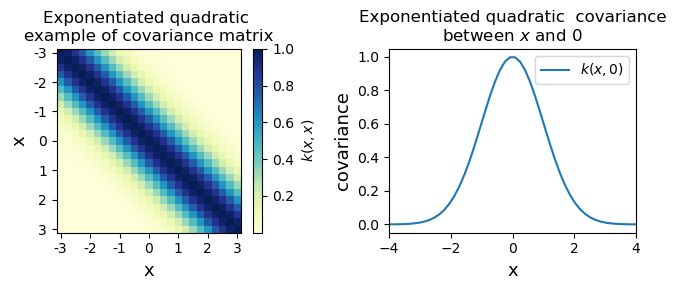

In [6]:
import scipy as sp
import pandas as pd
import matplotlib.cm as cm

# Define the exponentiated quadratic 
def exponentiated_quadratic(xa, xb):
    """Exponentiated quadratic  with σ=1"""
    # L2 distance (Squared Euclidian)
    sq_norm = -0.5 * sp.spatial.distance.cdist(xa, xb, 'sqeuclidean')
    return np.exp(sq_norm)

# Illustrate covariance matrix and function
# Show covariance matrix example from exponentiated quadratic
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3))
xlim = (-3, 3)
X = np.expand_dims(np.linspace(*xlim, 25), 1)
Σ = exponentiated_quadratic(X, X)
# Plot covariance matrix
im = ax1.imshow(Σ, cmap=cm.YlGnBu)
cbar = plt.colorbar(
    im, ax=ax1, fraction=0.045, pad=0.05)
cbar.ax.set_ylabel('$k(x,x)$', fontsize=10)
ax1.set_title(('Exponentiated quadratic \n' 'example of covariance matrix'))
ax1.set_xlabel('x', fontsize=13)
ax1.set_ylabel('x', fontsize=13)
ticks = list(range(xlim[0], xlim[1]+1))
ax1.set_xticks(np.linspace(0, len(X)-1, len(ticks)))
ax1.set_yticks(np.linspace(0, len(X)-1, len(ticks)))
ax1.set_xticklabels(ticks)
ax1.set_yticklabels(ticks)
ax1.grid(False)

# Show covariance with X=0
xlim = (-4, 4)
X = np.expand_dims(np.linspace(*xlim, num=50), 1)
zero = np.array([[0]])
Σ0 = exponentiated_quadratic(X, zero)
ax2.plot(X[:,0], Σ0[:,0], label='$k(x,0)$')
ax2.set_xlabel('x', fontsize=13)
ax2.set_ylabel('covariance', fontsize=13)
ax2.set_title(('Exponentiated quadratic  covariance\n' 'between $x$ and $0$'))
# ax2.set_ylim([0, 1.1])
ax2.set_xlim(*xlim)
ax2.legend(loc=1)

fig.tight_layout()
plt.show()
    

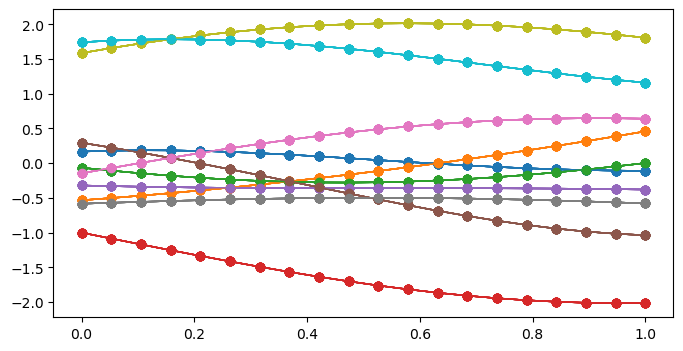

In [7]:
# Define the kernel RBF
def kernel(a, b):
    sqdist = np.sum(a**2,axis=1).reshape(-1,1) + np.sum(b**2,1) - 2*np.dot(a, b.T)
    # np.sum( ,axis=1) means adding all elements columnly; .reshap(-1, 1) add one dimension to make (n,) become (n,1)
    return np.exp(-.5 * sqdist)

n = 20  
m = 10
X = np.linspace(0, 1, n).reshape(-1,1)   
K_ = kernel(X, X)                  # k(x_star, x_star)        
mean = np.zeros(n)
cov = np.eye(n)

f_prior = np.random.multivariate_normal(mean, K_, m).T

plt.figure(figsize=(8, 4))
Xshow = np.linspace(0, 1, n).reshape(-1,1)   # n puntos de prueba en el rango (0, 1)
for i in range(m):
    plt.plot(Xshow, f_prior, '-o', linewidth=1)
    

Obtenemos líneas mucho más suaves que se asemejan más a funciones. Cuando la dimensión de la Gaussiana aumenta, ya no es necesario conectar puntos. Cuando la dimensión se vuelve infinita, hay un punto que representa cualquier entrada posible. Vamos a graficar `m=200` muestras de una Gaussiana de `n=200-D` para tener una idea de cómo se ven las funciones con infinitos parámetros. 

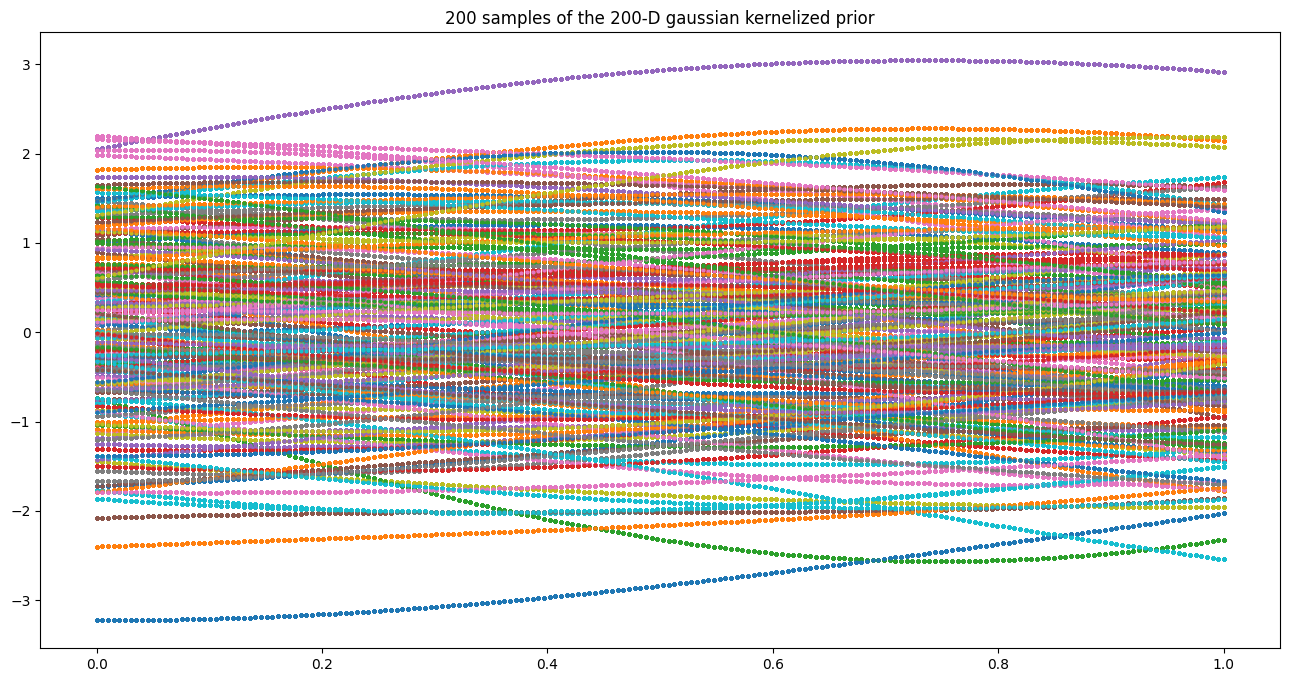

In [12]:
n = 200         
m = 200
X = np.linspace(0, 1, n).reshape(-1,1)   
K_ = kernel(X, X)                    # k(x_star, x_star)        
mean = np.zeros(n)
cov = np.eye(n)

f_prior = np.random.multivariate_normal(mean, K_, m).T

plt.figure(figsize=(16,8))
for i in range(m):
    plt.plot(X, f_prior, 'o', linewidth=1, markersize=2, markeredgewidth=1)
plt.title('200 samples of the 200-D gaussian kernelized prior');

### Descomposición de Cholesky

La descomposición de Cholesky es un algoritmo que toma tu matriz de kernel $K$ (tu "mapa de correlaciones") y la descompone en el producto de una matriz $L$ y su transpuesta $L^T$, donde $L L^T = K$. Es, conceptualmente, la raíz cuadrada de una matriz. Se hace para encontrar la matriz transformadora L. Esta matriz L es la "receta" o el "plano topográfico" que nos dice exactamente cómo a partir de datos aleatorios e independientes (z) para canalizarla y formar una matriz que tenga la estructura y las correlaciones que definimos en nuestro kernel. En resumen, la descomposición de Cholesky es el puente computacional que nos permite pasar de un ruido simple y sin estructura a una función suave y correlacionada que se parece a un fenómeno físico real.

$$
\mathbf{K} = \mathbf{L} \mathbf{L}^T
$$


#### ¿Para qué se usa exactamente $\mathbf{L}$?

Evaluar el kernel nos da los números de $\mathbf{K}$, pero para muestrear, predecir y entrenar un GP hay tres operaciones donde trabajar con $\mathbf{K}$ directamente es lento o numéricamente inestable:

**A. Para simular funciones del GP (sampling).** El computador solo sabe generar ruido blanco independiente $\mathbf{u} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$. Para convertir ese ruido en curvas suaves y correlacionadas según el kernel, se multiplica por $\mathbf{L}$:
$$\mathbf{f}_{\text{suave}} = \mathbf{L}\mathbf{u}$$
Sin Cholesky no se pueden generar simulaciones ni predicciones probabilísticas del modelo.

**B. Para resolver $\mathbf{K}^{-1}\mathbf{y}$ de forma eficiente y estable.** Calcular explícitamente la inversa de una matriz es costoso ($O(n^3)$) y propenso a errores de redondeo cuando hay puntos muy cercanos. Sustituyendo $\mathbf{K} = \mathbf{L}\mathbf{L}^T$, el sistema $\mathbf{L}\mathbf{L}^T \boldsymbol{\alpha} = \mathbf{y}$ se resuelve en dos pasos triangulares rápidos (sustitución hacia adelante y hacia atrás), sin invertir nada.

**C. Para calcular el log-determinante $\log|\mathbf{K}|$.** Entrenar el GP requiere maximizar la log-verosimilitud marginal, que exige el log-determinante de $\mathbf{K}$. Calcularlo directamente en una matriz grande es costoso, pero gracias a Cholesky es simplemente la suma de los logaritmos de la diagonal de $\mathbf{L}$:
$$\log|\mathbf{K}| = 2\sum_{i=1}^{n}\log(L_{ii})$$

En resumen: el **kernel** es el arquitecto que define las relaciones geométricas ideales entre los datos; la **matriz $\mathbf{K}$** es el plano de esa estructura; y **Cholesky** es el obrero que descompone ese plano en piezas triangulares fáciles de manipular, permitiendo invertir, evaluar la verosimilitud y simular sin que el cálculo colapse numéricamente.

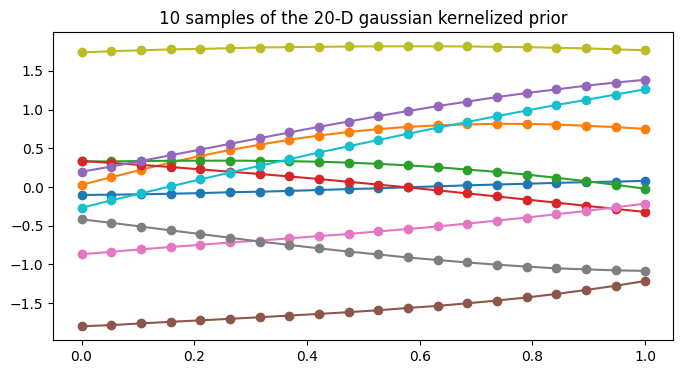

In [13]:
n = 20      
m = 10
X = np.linspace(0, 1, n).reshape(-1,1)  
K_ = kernel(X, X)                
L = np.linalg.cholesky(K_ + 1e-6*np.eye(n))

f_prior = np.dot(L, np.random.normal(size=(n,m)))

plt.figure(figsize=(8,4))
plt.plot(X, f_prior, '-o')
plt.title('10 samples of the 20-D gaussian kernelized prior');

Entonces, tenemos observaciones, y hemos estimado funciones $\mathbf{f}$ con estas observaciones. Ahora digamos que tenemos algunos puntos nuevos $\mathbf{X}_*$ donde queremos predecir $f(\mathbf{X}_*)$.

<img src="https://github.com/jwangjie/Gaussian-Process-Regression-Tutorial/blob/master/img/mvn.png?raw=1" width="500"/>

La distribución conjunta de $\mathbf{f}$ y $\mathbf{f}_*$ se puede modelar como:

$$ \begin{pmatrix}\mathbf{f} \\ \mathbf{f}_*\end{pmatrix} \sim\mathcal{N}\left(\begin{pmatrix}m(\mathbf{X})\\ m(\mathbf{X}_*)\end{pmatrix}, \begin{pmatrix}\mathbf{K} & \mathbf{K}_* \\ \mathbf{K}_*^T & \mathbf{K}_{**}\end{pmatrix}\right) $$

donde $\mathbf{K}=\kappa(\mathbf{X}, \mathbf{X})$, $\mathbf{K}_* = \kappa(\mathbf{X}, \mathbf{X}_*)$ y $\mathbf{K}_{**}=\kappa(\mathbf{X}_*, \mathbf{X}_*)$. Y $\begin{pmatrix}m(\mathbf{X})\\ m(\mathbf{X}_*)\end{pmatrix} = \mathbf{0}$

Esto modela una distribución conjunta $p(\mathbf{f}, \mathbf{f}_* \, \vert \, \mathbf{X}, \mathbf{X}_*)$, pero queremos la distribución condicional sobre $\mathbf{f}_*$ solamente, que es $p(\mathbf{f}_* \, \vert \, \mathbf{f}, \mathbf{X}, \mathbf{X}_*)$. El proceso de derivación de la distribución conjunta $p(\mathbf{f}, \mathbf{f}_* \, \vert \, \mathbf{X}, \mathbf{X}_*)$ a la condicional $p(\mathbf{f}_* \, \vert \, \mathbf{f}, \mathbf{X}, \mathbf{X}_*)$ usa la distribución marginal y condicional, y obtenemos la ecuación:

$$\mathbf{f}_* \, \vert \, \mathbf{f}, \mathbf{X}, \mathbf{X}_* \sim \mathcal{N} (\mathbf{K}_*^T \mathbf{K}^{-1} \mathbf{f}, \: \mathbf{K}_{**}-\mathbf{K}_*^T \mathbf{K}^{-1} \mathbf{K}_*) $$

Estas corresponden a las mismas ecuaciones descritas anteriormente. La nueva media de $x_1$ dado que observamos $x_2=a$.

$$
\mu_{1|2} = \mu_1 + \frac{\sigma_{12}}{\sigma_2^2} (a - \mu_2)
$$

Si asumimos que las medias $\mu_1$ y $\mu_2$ son cero, la ecuación se simplifica a:

$$\mu_{1|2} = \frac{\sigma_{12}}{\sigma_2^2} a $$

La media de las predicciones $\mathbf{f}_*$ dado que observamos los datos $\mathbf{f}$.

$$
\text{media}(\mathbf{f}_*) = \mathbf{K}_*^T \mathbf{K}^{-1} \mathbf{f}
$$

$\mathbf{K}_*^T$ es el análogo de la covarianza $\sigma_{12}$ (o más bien $\sigma_{21}$, que es lo mismo). $\mathbf{K}^{−1}$  (multiplicar por la inversa) es el análogo de dividir entre la varianza $\frac{1}{\sigma_2^2}$. $\mathbf{f}$ es el análogo del valor observado $a$.

La nueva varianza de $x_1$(nuestra incertidumbre reducida).

$$
\sigma^2_{1|2} = \sigma_1^2 - \frac{\sigma_{12}^2}{\sigma_2^2}
$$

Podemos reescribir el segundo término como $\frac{\sigma_{12}}{\sigma_{21}\sigma_{22}}$ ya que $\sigma_{12}=\sigma_{21}.$

La nueva matriz de covarianza para las predicciones $\mathbf{f}_*$.

$$
\text{cov}(\mathbf{f}_*) = \mathbf{K}_{**} - \mathbf{K}_*^T \mathbf{K}^{-1} \mathbf{K}_*
$$

donde $\mathbf{K}_{**}$ es el análogo de la varianza original $\sigma_1^2$. Y por el otro lado, $\mathbf{K}_*^T \mathbf{K}^{-1} \mathbf{K}_*$ es el análogo matricial de $\frac{\sigma_{21}}{\sigma_{12}\sigma_{22}}$. Es el término que representa la reducción de la incertidumbre gracias a las observaciones.

Es realista modelar situaciones en las que no tenemos acceso a los valores de la función en sí, sino solo versiones ruidosas de ellos $y = f(x) + \epsilon$. Suponiendo ruido aditivo independiente e idénticamente distribuido con varianza $\sigma_n^2$, la a priori sobre las observaciones ruidosas se convierte en $cov(y) = \mathbf{K} + \sigma_n^2\mathbf{I}$. La distribución conjunta de los valores objetivos observados y los valores de la función en las ubicaciones de prueba bajo la a priori es

$$ \begin{pmatrix}\mathbf{y} \\ \mathbf{f}_*\end{pmatrix} \sim\mathcal{N}\left(\mathbf{0}, \begin{pmatrix}\mathbf{K} + \sigma_n^2\mathbf{I} & \mathbf{K}_* \\ \mathbf{K}_*^T & \mathbf{K}_{**}\end{pmatrix}\right) $$

Derivando la distribución condicional correspondiente a la ecuación 2.19 obtenemos las ecuaciones predictivas para la regresión de procesos Gaussianos como

$$\mathbf{\bar{f}_*} \, \vert \, \mathbf{X}, \mathbf{y}, \mathbf{X}_* \sim \mathcal{N} \left(\mathbf{\bar{f}_*}, cov(\mathbf{f}_*)\right) $$

donde,
$$\mathbf{\bar{f}_*} \overset{\Delta}{=} \mathbb{E} [\mathbf{\bar{f}_*} \, \vert \, \mathbf{X}, \mathbf{y}, \mathbf{X}_*] = \mathbf{K}_*^T [\mathbf{K} + \sigma_y^2\mathbf{I}]^{-1} \mathbf{y} $$

$$cov(\mathbf{f}_*) = \mathbf{K}_{**} - \mathbf{K}_*^T [\mathbf{K} + \sigma_y^2\mathbf{I}]^{-1} \mathbf{K}_* $$

### ¿Por qué media a priori igual a cero?

En la derivación anterior asumimos $m(\mathbf{X}) = \mathbf{0}$. Esta elección es extremadamente común en GP y suele malinterpretarse como si el modelo "no supiera" nada, pero tiene una lógica bayesiana precisa:

1. **A priori (media = 0):** antes de observar datos de entrenamiento, el modelo no asume ninguna tendencia de fondo — es la opción más neutral posible.
2. **A posteriori (condicionamiento):** al observar los datos reales, la distribución conjunta se condiciona y la superficie predictiva se eleva o desciende suavemente para ajustarse a esos datos, sin importar que la media a priori fuera cero.
3. **Extrapolación:** el único efecto real de la media cero a priori aparece lejos de cualquier dato observado — ahí la predicción regresa gradualmente hacia cero con incertidumbre máxima. Por esta razón, cuando los datos reales no oscilan alrededor de cero (p. ej. elevaciones de 1500 m s.n.m.), muchas implementaciones activan una media constante (`ConstantMean`) o lineal en vez de cero.

**Equivalencia con Kriging Simple:** un GP con media de fondo fija y conocida es matemáticamente equivalente al **Kriging Simple**. Ajustar un GP de media cero equivale exactamente a restar el promedio global a los datos, correr un Kriging Simple, y sumar de nuevo ese promedio al mapa resultante.

### Ejemplo GP con 1 variable y sin ruido

Primeros definimos una función que nos estima el valor medio y la covarianza en un GP ingresando como datos una covariable $X1$ con sus correspondientes $y1$, y datos nuevos para predecir de la covariable denominado $X2$, y una función kernel definida por el ususario.

In [9]:
# Gaussian process posterior
from scipy import linalg
def GP(X1, y1, X2, kernel_func):
    """
    Calculate the posterior mean and covariance matrix for y2
    based on the corresponding input X2, the observations (y1, X1), 
    and the prior kernel function.
    """
    # Kernel of the observations
    Σ11 = kernel_func(X1, X1)
    # Kernel of observations vs to-predict
    Σ12 = kernel_func(X1, X2)
    # Solve
    solved = sp.linalg.solve(Σ11, Σ12, assume_a='pos').T
    # Compute posterior mean
    μ2 = solved @ y1
    # Compute the posterior covariance
    Σ22 = kernel_func(X2, X2)
    Σ2 = Σ22 - (solved @ Σ12)
    return μ2, Σ2  # mean, covariance

Con esta función construida, vamos a generar unos datos sintéticos a partir de una función verdadera, en este caso *Sen(x)*, la cual siempre se desconoce, en este caso la estamos creando para poder generar los datos observados para el ejemplo. En la vida real, esta función se desconoce y lo que tenemos son solo los datos observados.

In [10]:
# Compute the posterior mean and covariance

# Definir la función verdadera sobre la que queremos hacer la regresión
f_sin = lambda x: (np.sin(x)).flatten()

n1 = 8  # Número de puntos sobre los que se condiciona (puntos de entrenamiento)
n2 = 75  # Número de puntos en la posterior (puntos de prueba)
ny = 5  # Número de funciones que se muestrean de la posterior
domain = (-6, 6)

# Muestrear observaciones (X1, y1) de la función
X1 = np.random.uniform(domain[0]+2, domain[1]-2, size=(n1, 1))
y1 = f_sin(X1)

# Predict points at uniform spacing to capture function
X2 = np.linspace(domain[0], domain[1], n2).reshape(-1, 1)

Ya generamos entonces *X1*, *y1* y los valores a predecir *X2*. Con estos datos podemos entonces implementar la función que creamos al inicio y que permite implementar GP. Como kernel utilizaremos la función que creamos anteriormente denominada *exponentiated_quadratic*.

In [11]:

# Compute posterior mean and covariance
μ2, Σ2 = GP(X1, y1, X2, exponentiated_quadratic)

# Calcular la desviación estándar en los puntos de prueba que se van a graficar
σ2 = np.sqrt(np.diag(Σ2))

Ahora, vamos a graficar la función real *Sen(x)* con el valor medio que se obtuvo con el GP un intervalor de dos desviaciones estandar, que se obtiene de los resultados del GP, y graficaremos los puntos observados $x1$ y $y1$.

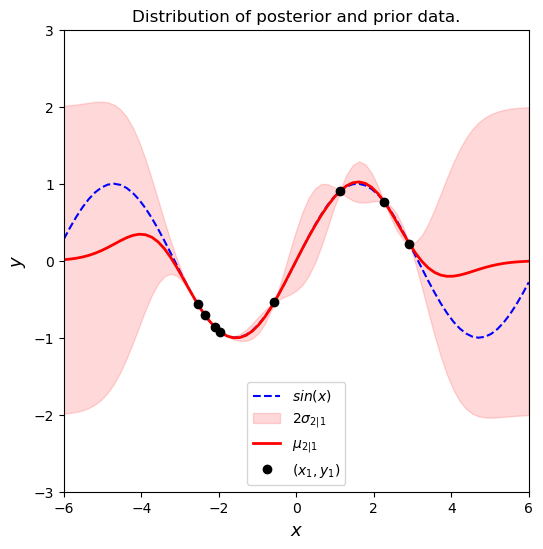

In [12]:
# Plot the postior distribution and some samples
fig, ax = plt.subplots(figsize=(6, 6))

# Graficar la distribución de la función (media, covarianza)
ax.plot(X2, f_sin(X2), 'b--', label='$sin(x)$')
ax.fill_between(X2.flat, μ2-2*σ2, μ2+2*σ2, color='red', alpha=0.15, label='$2 \sigma_{2|1}$')
ax.plot(X2, μ2, 'r-', lw=2, label='$\mu_{2|1}$')
ax.plot(X1, y1, 'ko', linewidth=2, label='$(x_1, y_1)$')
ax.set_xlabel('$x$', fontsize=13)
ax.set_ylabel('$y$', fontsize=13)
ax.set_title('Distribution of posterior and prior data.')
ax.axis([domain[0], domain[1], -3, 3])
ax.legend();

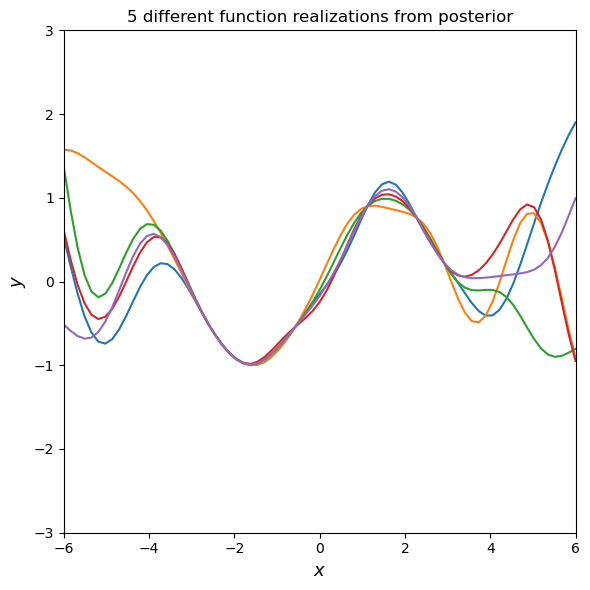

In [13]:
# Draw some samples of the posterior
y2 = np.random.multivariate_normal(mean=μ2, cov=Σ2, size=ny)

# Plot the postior distribution and some samples
fig, ax = plt.subplots(figsize=(6, 6))

# Plot some samples from this function
ax.plot(X2, y2.T, '-')
ax.set_xlabel('$x$', fontsize=13)
ax.set_ylabel('$y$', fontsize=13)
ax.set_title('5 different function realizations from posterior')
ax.axis([domain[0], domain[1], -3, 3])
ax.set_xlim([-6, 6])
plt.tight_layout()
plt.show()

### Ejemplo GP con 1 variable y con datos con ruido

De forma similar vamos a generar un ejemplo con datos sintéticos, pero en este caso incluiremos ruido propio de los datos.

In [18]:
# Gaussian process posterior with noisy obeservations
def GP_noise(X1, y1, X2, kernel_func, σ_noise):
    """
    Calculate the posterior mean and covariance matrix for y2
    based on the corresponding input X2, the noisy observations 
    (y1, X1), and the prior kernel function.
    """
    # Kernel of the noisy observations
    Σ11 = kernel_func(X1, X1) + ((σ_noise ** 2) * np.eye(n1))
    # Kernel of observations vs to-predict
    Σ12 = kernel_func(X1, X2)
    # Solve
    solved = sp.linalg.solve(Σ11, Σ12, assume_a='pos').T
    # Compute posterior mean
    μ2 = solved @ y1
    # Compute the posterior covariance
    Σ22 = kernel_func(X2, X2)
    Σ2 = Σ22 - (solved @ Σ12)
    return μ2, Σ2  # mean, covariance

In [15]:
σ_noise = 1.  # La desviación estándar del ruido
# Agregar un kernel de ruido a las muestras tomadas antes
y1 = y1 + ((σ_noise ** 2) * np.random.randn(n1))

In [19]:
# Compute the posterior mean and covariance
μ2, Σ2 = GP_noise(X1, y1, X2, exponentiated_quadratic, σ_noise)

# Calcular la desviación estándar en los puntos de prueba que se van a graficar
σ2 = np.sqrt(np.diag(Σ2))

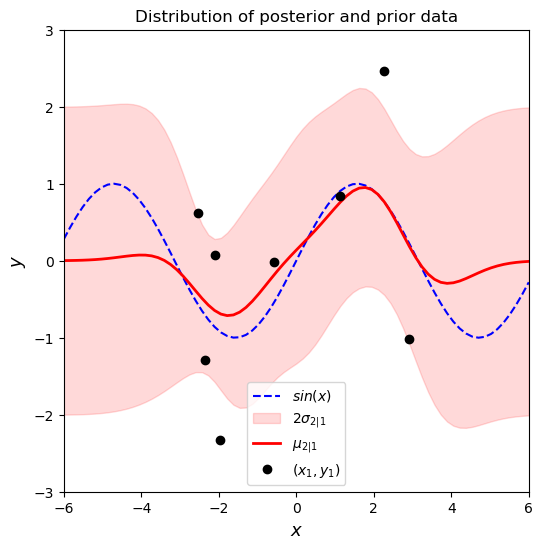

In [20]:
# Plot the postior distribution and some samples
fig, ax = plt.subplots(figsize=(6, 6))

# Graficar la distribución de la función (media, covarianza)
ax.plot(X2, f_sin(X2), 'b--', label='$sin(x)$')
ax.fill_between(X2.flat, μ2-2*σ2, μ2+2*σ2, color='red', 
                 alpha=0.15, label='$2\sigma_{2|1}$')
ax.plot(X2, μ2, 'r-', lw=2, label='$\mu_{2|1}$')
ax.plot(X1, y1, 'ko', linewidth=2, label='$(x_1, y_1)$')
ax.set_xlabel('$x$', fontsize=13)
ax.set_ylabel('$y$', fontsize=13)
ax.set_title('Distribution of posterior and prior data')
ax.axis([domain[0], domain[1], -3, 3])
ax.legend();


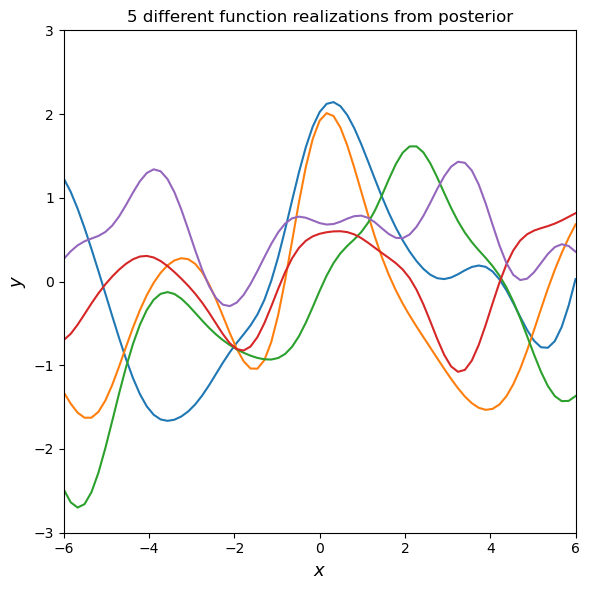

In [21]:
# Draw some samples of the posterior
y2 = np.random.multivariate_normal(mean=μ2, cov=Σ2, size=ny)

#Plot some samples from this function
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(X2, y2.T, '-')
ax.set_xlabel('$x$', fontsize=13)
ax.set_ylabel('$y$', fontsize=13)
ax.set_title('5 different function realizations from posterior')
ax.axis([domain[0], domain[1], -3, 3])
ax.set_xlim([-6, 6])
plt.tight_layout()
plt.show()

### Librerías

Hay varios paquetes o marcos disponibles para realizar Regresión de Procesos Gaussianos (GPR). 

Uno ligero es [sklearn.gaussian_process](https://scikit-learn.org/stable/modules/gaussian_process.html), cuya implementación simple, se puede realizar rápidamente.

Uno de los marcos de GP más conocidos es [GPy](https://sheffieldml.github.io/GPy/). GPy se ha desarrollado de manera bastante madura con explicaciones bien documentadas. GPy utiliza NumPy para realizar todos sus cálculos. Para tareas que no requieren cálculos intensivos y algoritmos muy actualizados, GPy es suficiente y más estable.

Para tareas de GPR que requieren mayores cálculos, la aceleración por GPU es especialmente preferida. [GPflow](https://www.gpflow.org/) se origina en GPy, y gran parte de la interfaz es similar. GPflow aprovecha **TensorFlow** como su backend computacional. Más diferencias técnicas entre los marcos GPy y GPflow se pueden encontrar [aquí](https://gpflow.readthedocs.io/en/master/intro.html#what-s-the-difference-between-gpy-and-gpflow).

[GPyTorch](https://gpytorch.ai/) es otro marco que proporciona aceleración por GPU a través de **PyTorch**. Contiene algoritmos de GP muy actualizados. Al igual que GPflow, GPyTorch proporciona gradientes automáticos. Por lo tanto, modelos complejos, como incrustar redes neuronales profundas en modelos GP, pueden desarrollarse más fácilmente.

### Prior & Posterior con diferentes Kernel

[RBF(length_scale=1), RationalQuadratic(alpha=1, length_scale=1), ExpSineSquared(length_scale=1, periodicity=10), DotProduct(sigma_0=1) ** 2, Matern(length_scale=1, nu=1.5)] 



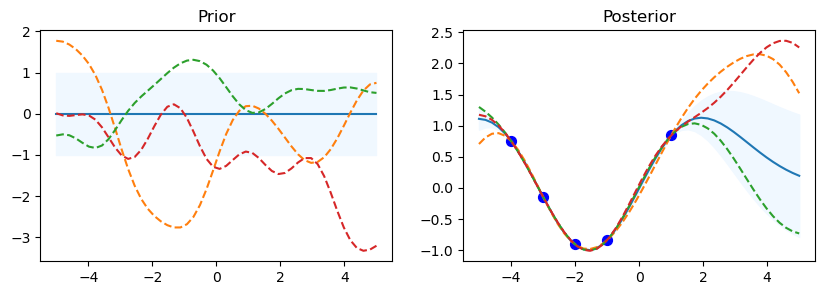

gp.kernel_ RBF(length_scale=1.93)
gp.log_marginal_likelihood: -3.444937833462115
-------------------------------------------------- 




/home/evaristizabalg/anaconda3/envs/ml/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter alpha is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


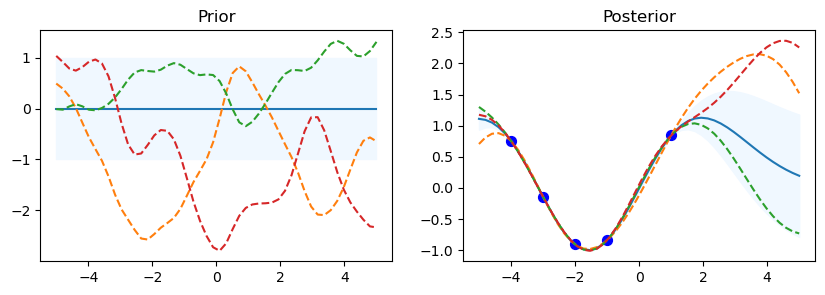

gp.kernel_ RationalQuadratic(alpha=1e+05, length_scale=1.93)
gp.log_marginal_likelihood: -3.4449718909150966
-------------------------------------------------- 




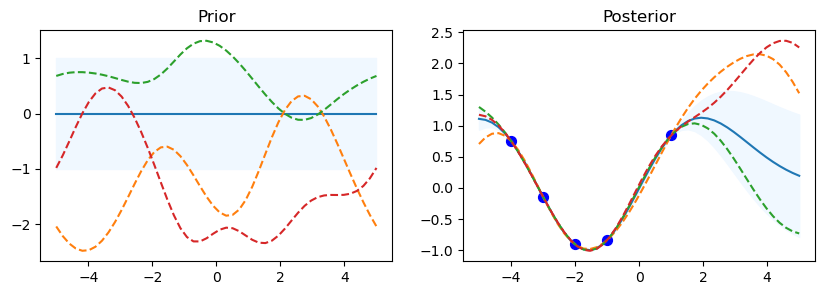

gp.kernel_ ExpSineSquared(length_scale=0.000524, periodicity=2.31e+04)
gp.log_marginal_likelihood: -3.444938145492622
-------------------------------------------------- 




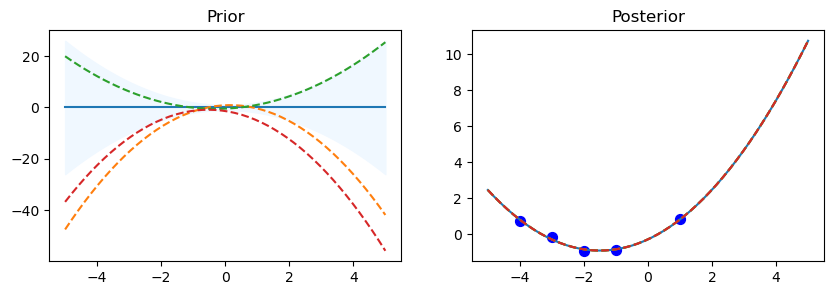

gp.kernel_ DotProduct(sigma_0=0.998) ** 2
gp.log_marginal_likelihood: -150204291.56018084
-------------------------------------------------- 




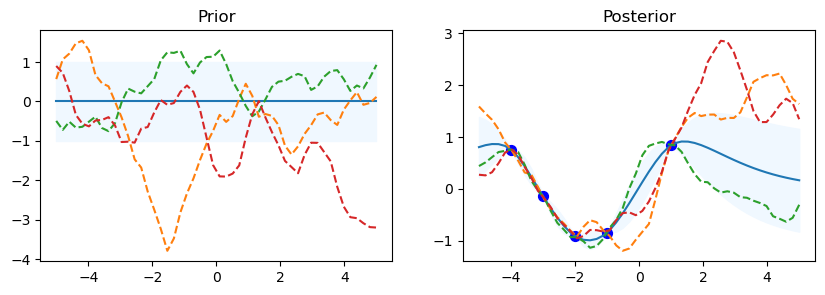

gp.kernel_ Matern(length_scale=1.99, nu=1.5)
gp.log_marginal_likelihood: -5.131637070524745
-------------------------------------------------- 




In [23]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process import kernels

np.random.seed(0)
n=50
kernel_ =[kernels.RBF (), kernels.RationalQuadratic(), kernels.ExpSineSquared(periodicity=10.0),kernels.DotProduct(sigma_0=1.0)**2,kernels.Matern()]
print(kernel_, '\n')
for kernel in kernel_:

    # Gaussian process
    gp = GaussianProcessRegressor(kernel=kernel)
# Prior
    x_test = np.linspace(-5, 5, n).reshape(-1, 1)
    mu_prior, sd_prior = gp.predict(x_test, return_std=True)
    samples_prior = gp.sample_y(x_test, 3)

# plot

    plt.figure(figsize=(10, 3))
    plt.subplot(1, 2, 1)
    plt.plot(x_test, mu_prior)
    plt.fill_between(x_test.ravel(), mu_prior - sd_prior,mu_prior + sd_prior, color='aliceblue')
    plt.plot(x_test, samples_prior, '--')
    plt.title('Prior')

# Fit

    x_train = np.array([-4, -3, -2, -1, 1]).reshape(-1, 1)
    y_train = np.sin(x_train)
    gp.fit(x_train, y_train)

#posterior

    mu_post, sd_post = gp.predict(x_test, return_std=True)
    mu_post = mu_post.reshape(-1)
    samples_post = np.squeeze(gp.sample_y(x_test, 3))

# plot

    plt.subplot(1, 2, 2)
    plt.plot(x_test, mu_post)
    plt.fill_between(x_test.ravel(), mu_post - sd_post,mu_post + sd_post, color='aliceblue')
    plt.plot(x_test, samples_post, '--')
    plt.scatter(x_train, y_train, c='blue', s=50)
    plt.title('Posterior')

    plt.show()

    print("gp.kernel_", gp.kernel_)
    print("gp.log_marginal_likelihood:",
    gp.log_marginal_likelihood(gp.kernel_.theta))

    print('-'*50, '\n\n')

### RBF & Linear

Los GP estan determinados por la función de *kernel* utilizada y sus hiperparámetros. A continuación vamos a ver dos funciones que crean dos tipos de kernel comunmente utilizadas *RBF y Lineal*, y vamos a variar sus hiperparámetros para observar y comparar los cambios en la matriz de covarianza.

In [24]:
def cov_linear(x,x2=None,theta=1):
        if x2 is None:
            return np.dot(x, x.T)*theta
        else:
            return np.dot(x, x2.T)*theta
    
        
def cov_RBF(x, x2=None, theta=np.array([1,1])):        
        """
        Compute the Euclidean distance between each row of X and X2, or between
        each pair of rows of X if X2 is None and feed it to the kernel.
        """
        variance = theta[0]
        lengthscale = theta[1]
        if x2 is None:
            xsq = np.sum(np.square(x),1)
            r2 = -2.*np.dot(x,x.T) + (xsq[:,None] + xsq[None,:])
            r = np.sqrt(r2)/lengthscale
        else:
            x1sq = np.sum(np.square(x),1)
            x2sq = np.sum(np.square(x2),1)
            r2 = -2.*np.dot(x, x2.T) + x1sq[:,None] + x2sq[None,:]
            r = np.sqrt(r2)/lengthscale

        return variance * np.exp(-0.5 * r**2)

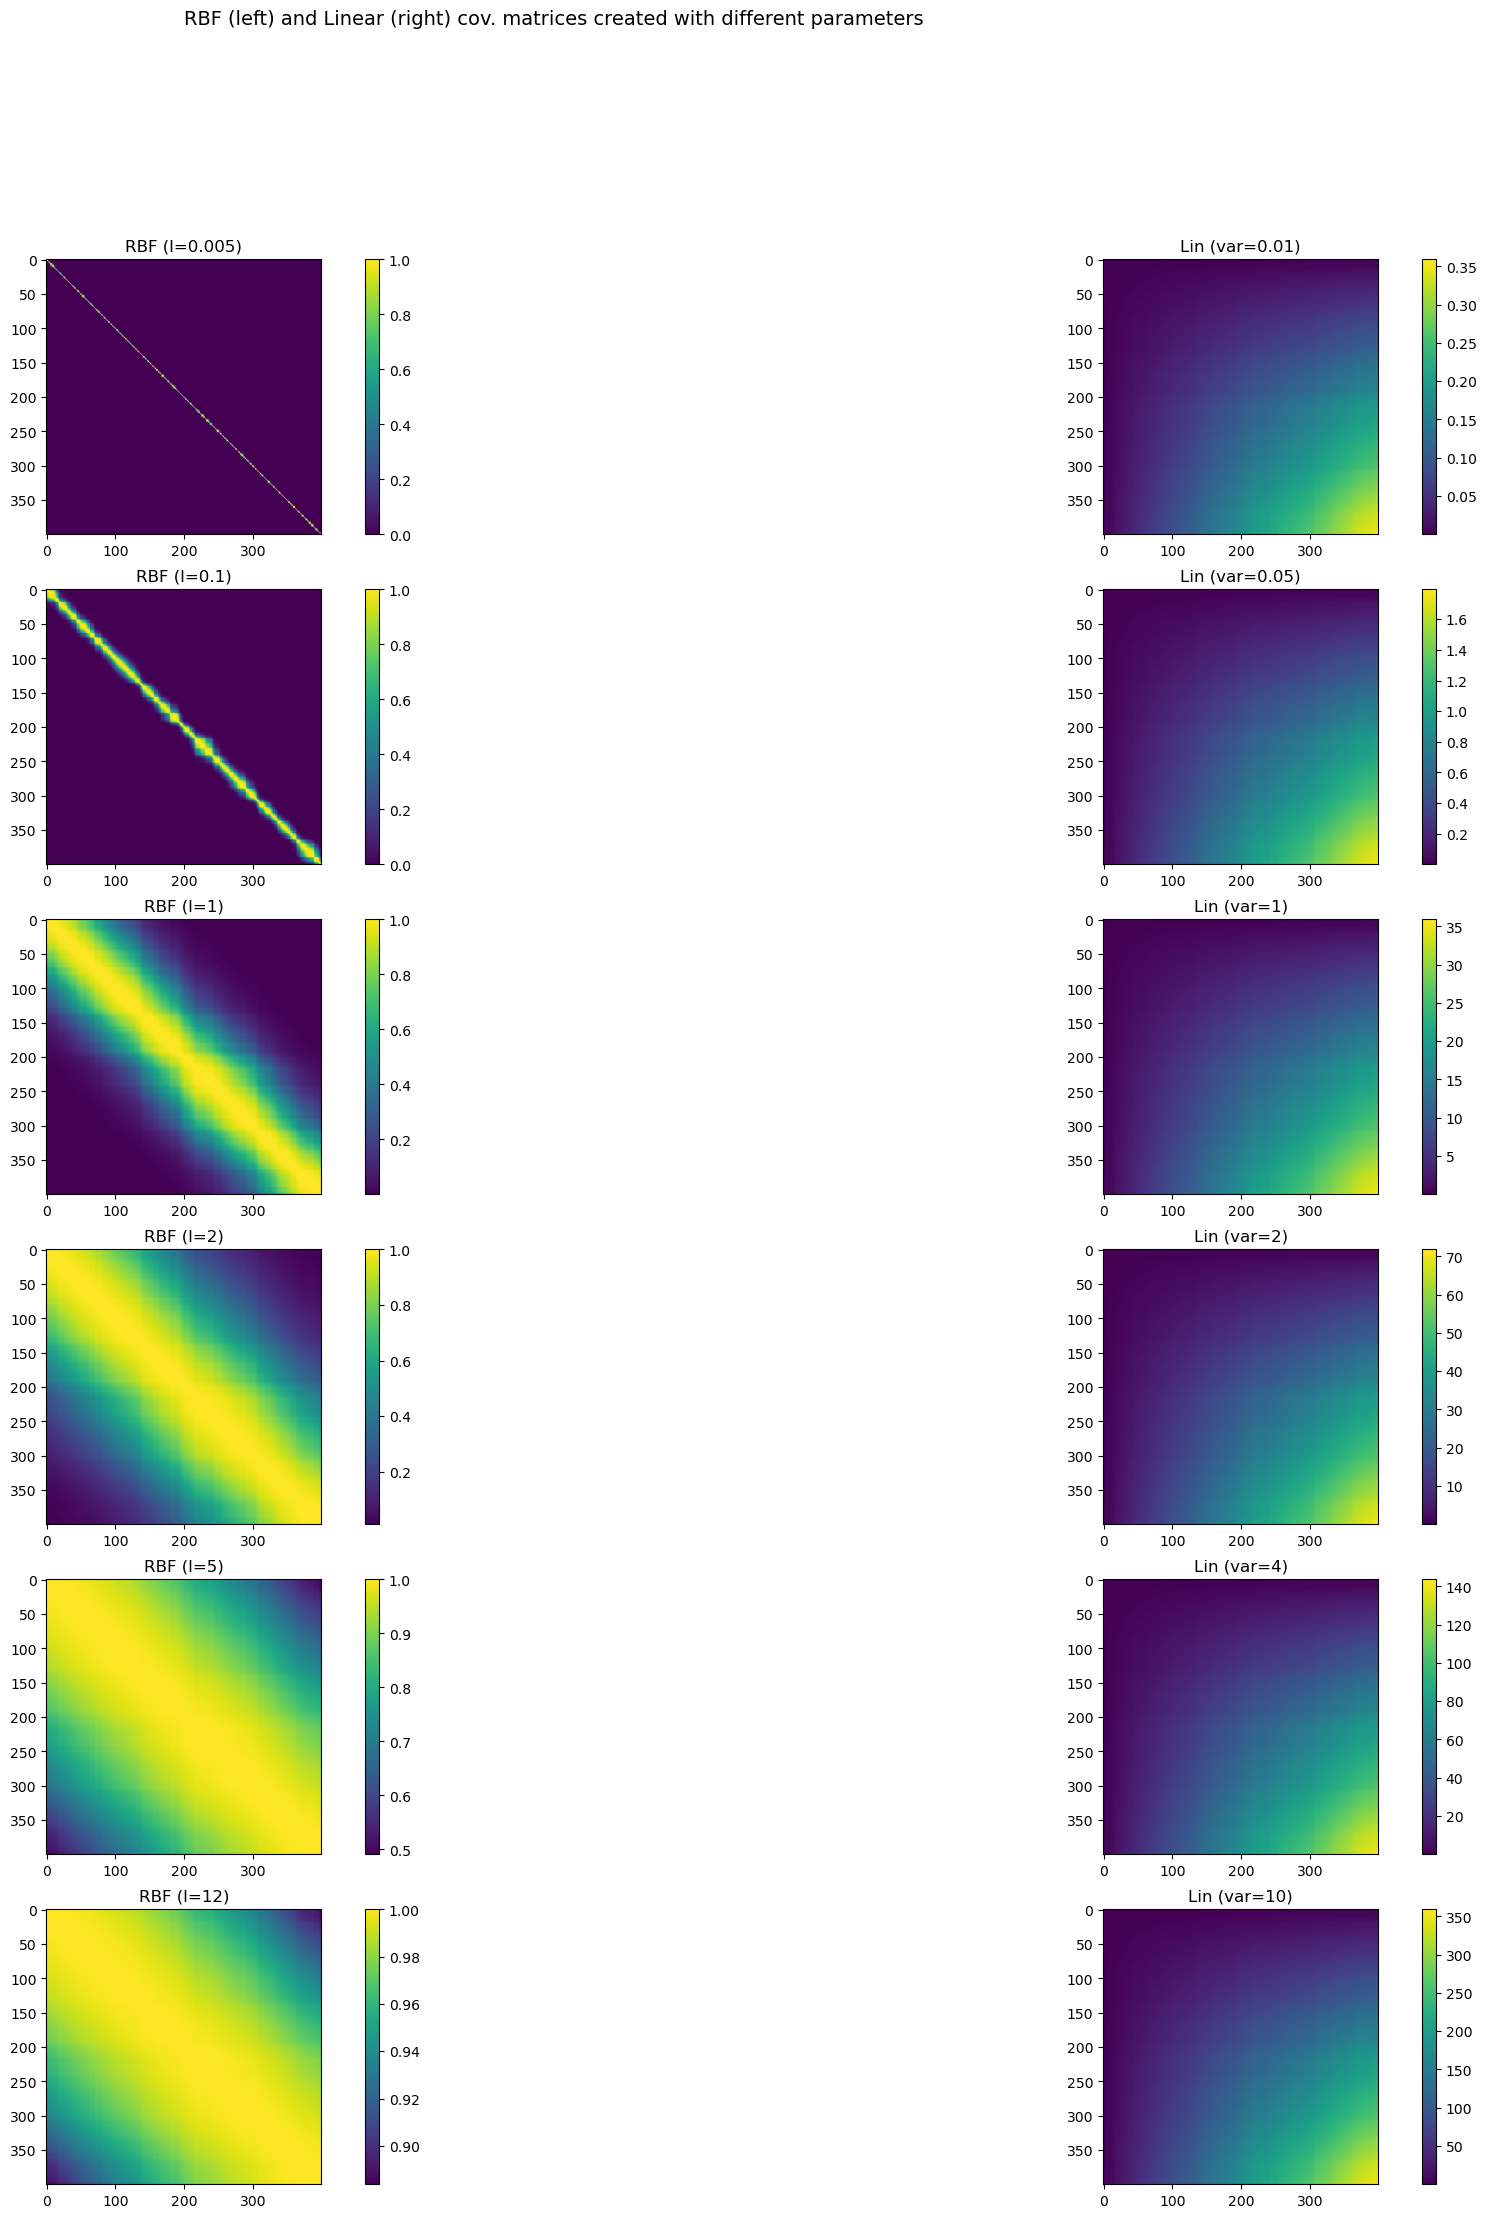

In [25]:
X = np.sort(np.random.rand(400, 1) * 6 , axis=0)

params_linear = [0.01, 0.05, 1, 2, 4, 10]
params_rbf    = [0.005, 0.1, 1, 2, 5, 12]
K = len(params_linear)

plt.figure(figsize=(25,25))
j=1
for i in range(K):
    plt.subplot(K,2,j)
    K_rbf = cov_RBF(X,X,theta=np.array([1,params_rbf[i]]))
    plt.imshow(K_rbf)
    plt.colorbar()
    plt.gca().set_title('RBF (l=' + str(params_rbf[i]) + ')')
    
    plt.subplot(K,2,j+1)
    K_lin = cov_linear(X,X,theta=params_linear[i])
    plt.imshow(K_lin)
    plt.colorbar()
    plt.gca().set_title('Lin (var=' + str(params_linear[i]) + ')')
    
    j+=2
    
plt.suptitle('RBF (left) and Linear (right) cov. matrices created with different parameters', fontsize=14);

Ahora vamos a generar funciones, en este ejemplo 5, a partir de la matriz de covarianza con RBF y diferentes hiperparámetros.

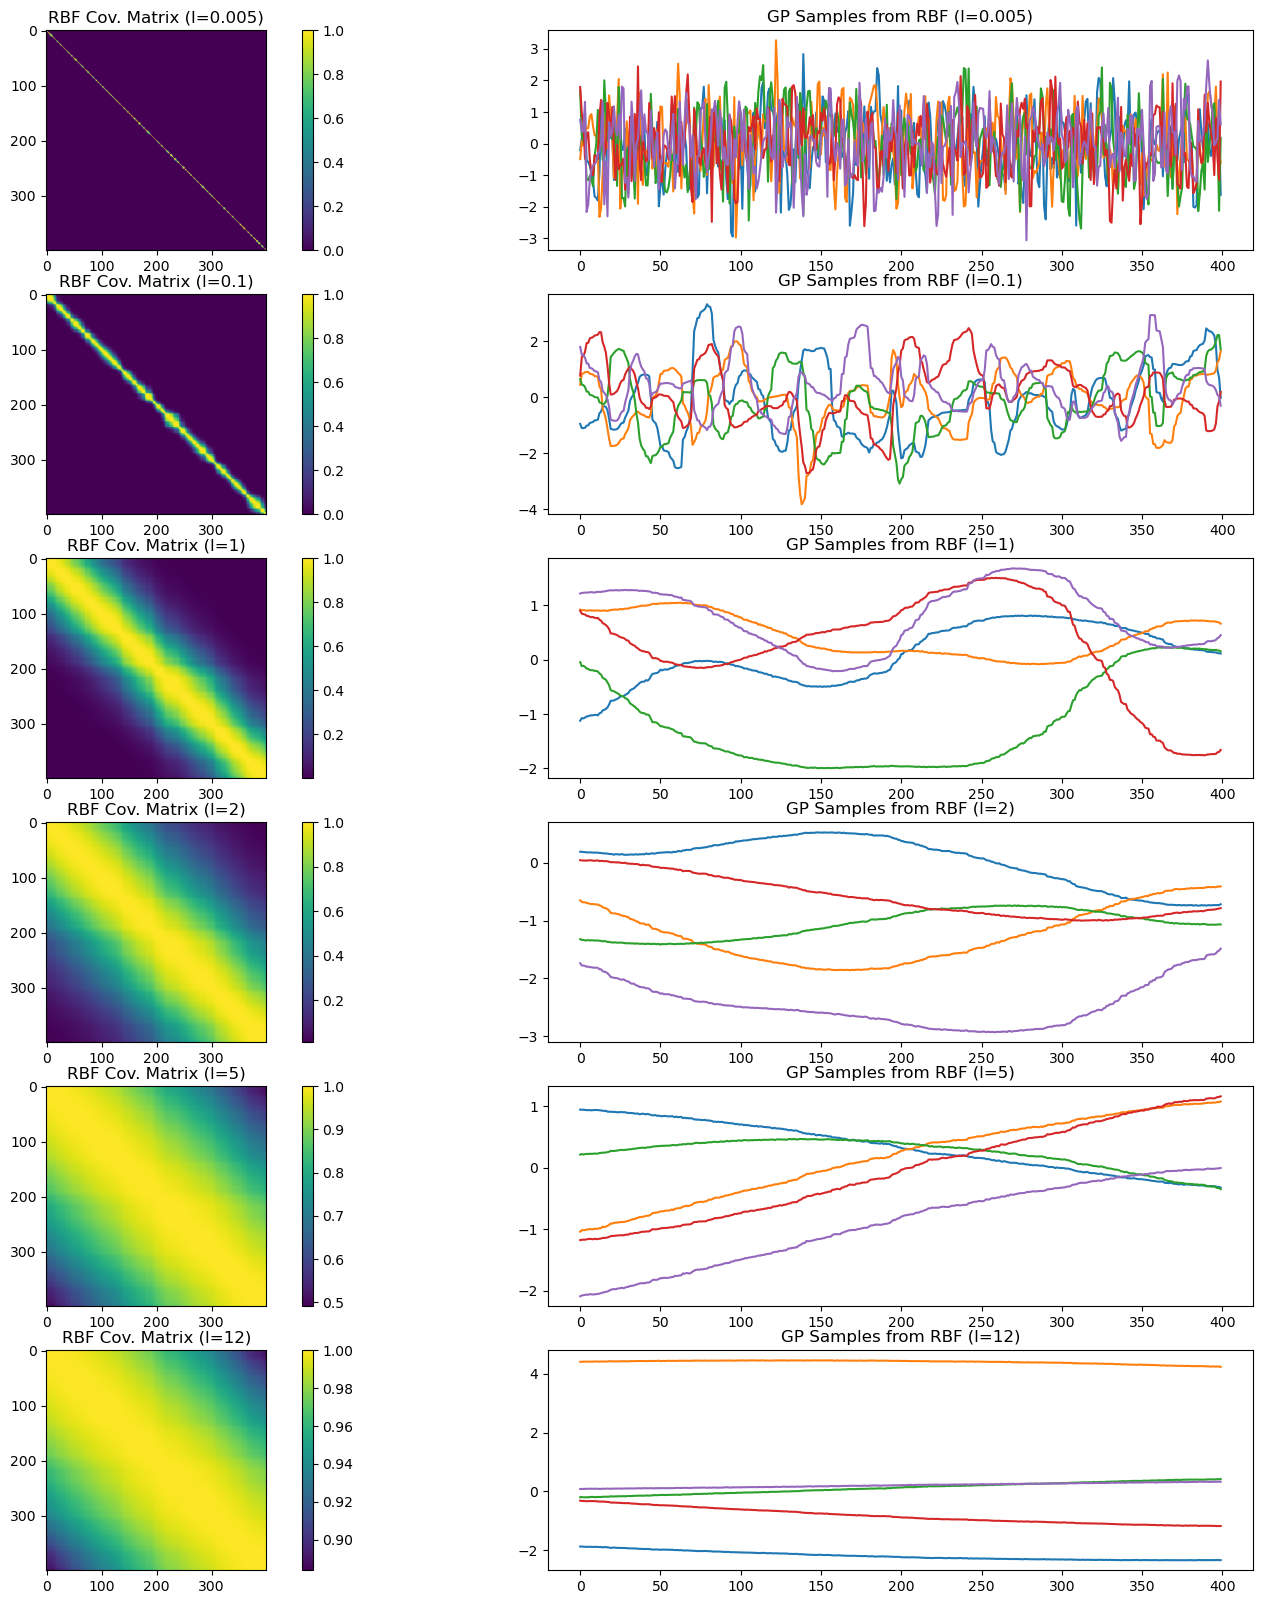

In [27]:
plt.figure(figsize=(20,20))
num_samples=5
j=1
for i in range(K):
    plt.subplot(K,2,j)
    K_rbf = cov_RBF(X,X,theta=np.array([1,params_rbf[i]]))
    plt.imshow(K_rbf)
    plt.colorbar()
    plt.gca().set_title('RBF Cov. Matrix (l=' + str(params_rbf[i]) + ')')
    
    plt.subplot(K,2,j+1)
    # Assume a GP with zero mean
    mu=np.zeros((1,K_rbf.shape[0]))[0,:]
    for s in range(num_samples):
        # El jitter es un pequeño ruido que se suma a la diagonal para garantizar que la matriz sea definida positiva
        jitter = 1e-5*np.eye(K_rbf.shape[0])
        sample = np.random.multivariate_normal(mean=mu, cov=K_rbf+jitter)
        plt.plot(sample)
    plt.gca().set_title('GP Samples from RBF (l=' + str(params_rbf[i]) + ')')
    j+=2

A continuación se presentan funciones de kernel de la librearía *sklearn* de 1 dimension (Q).

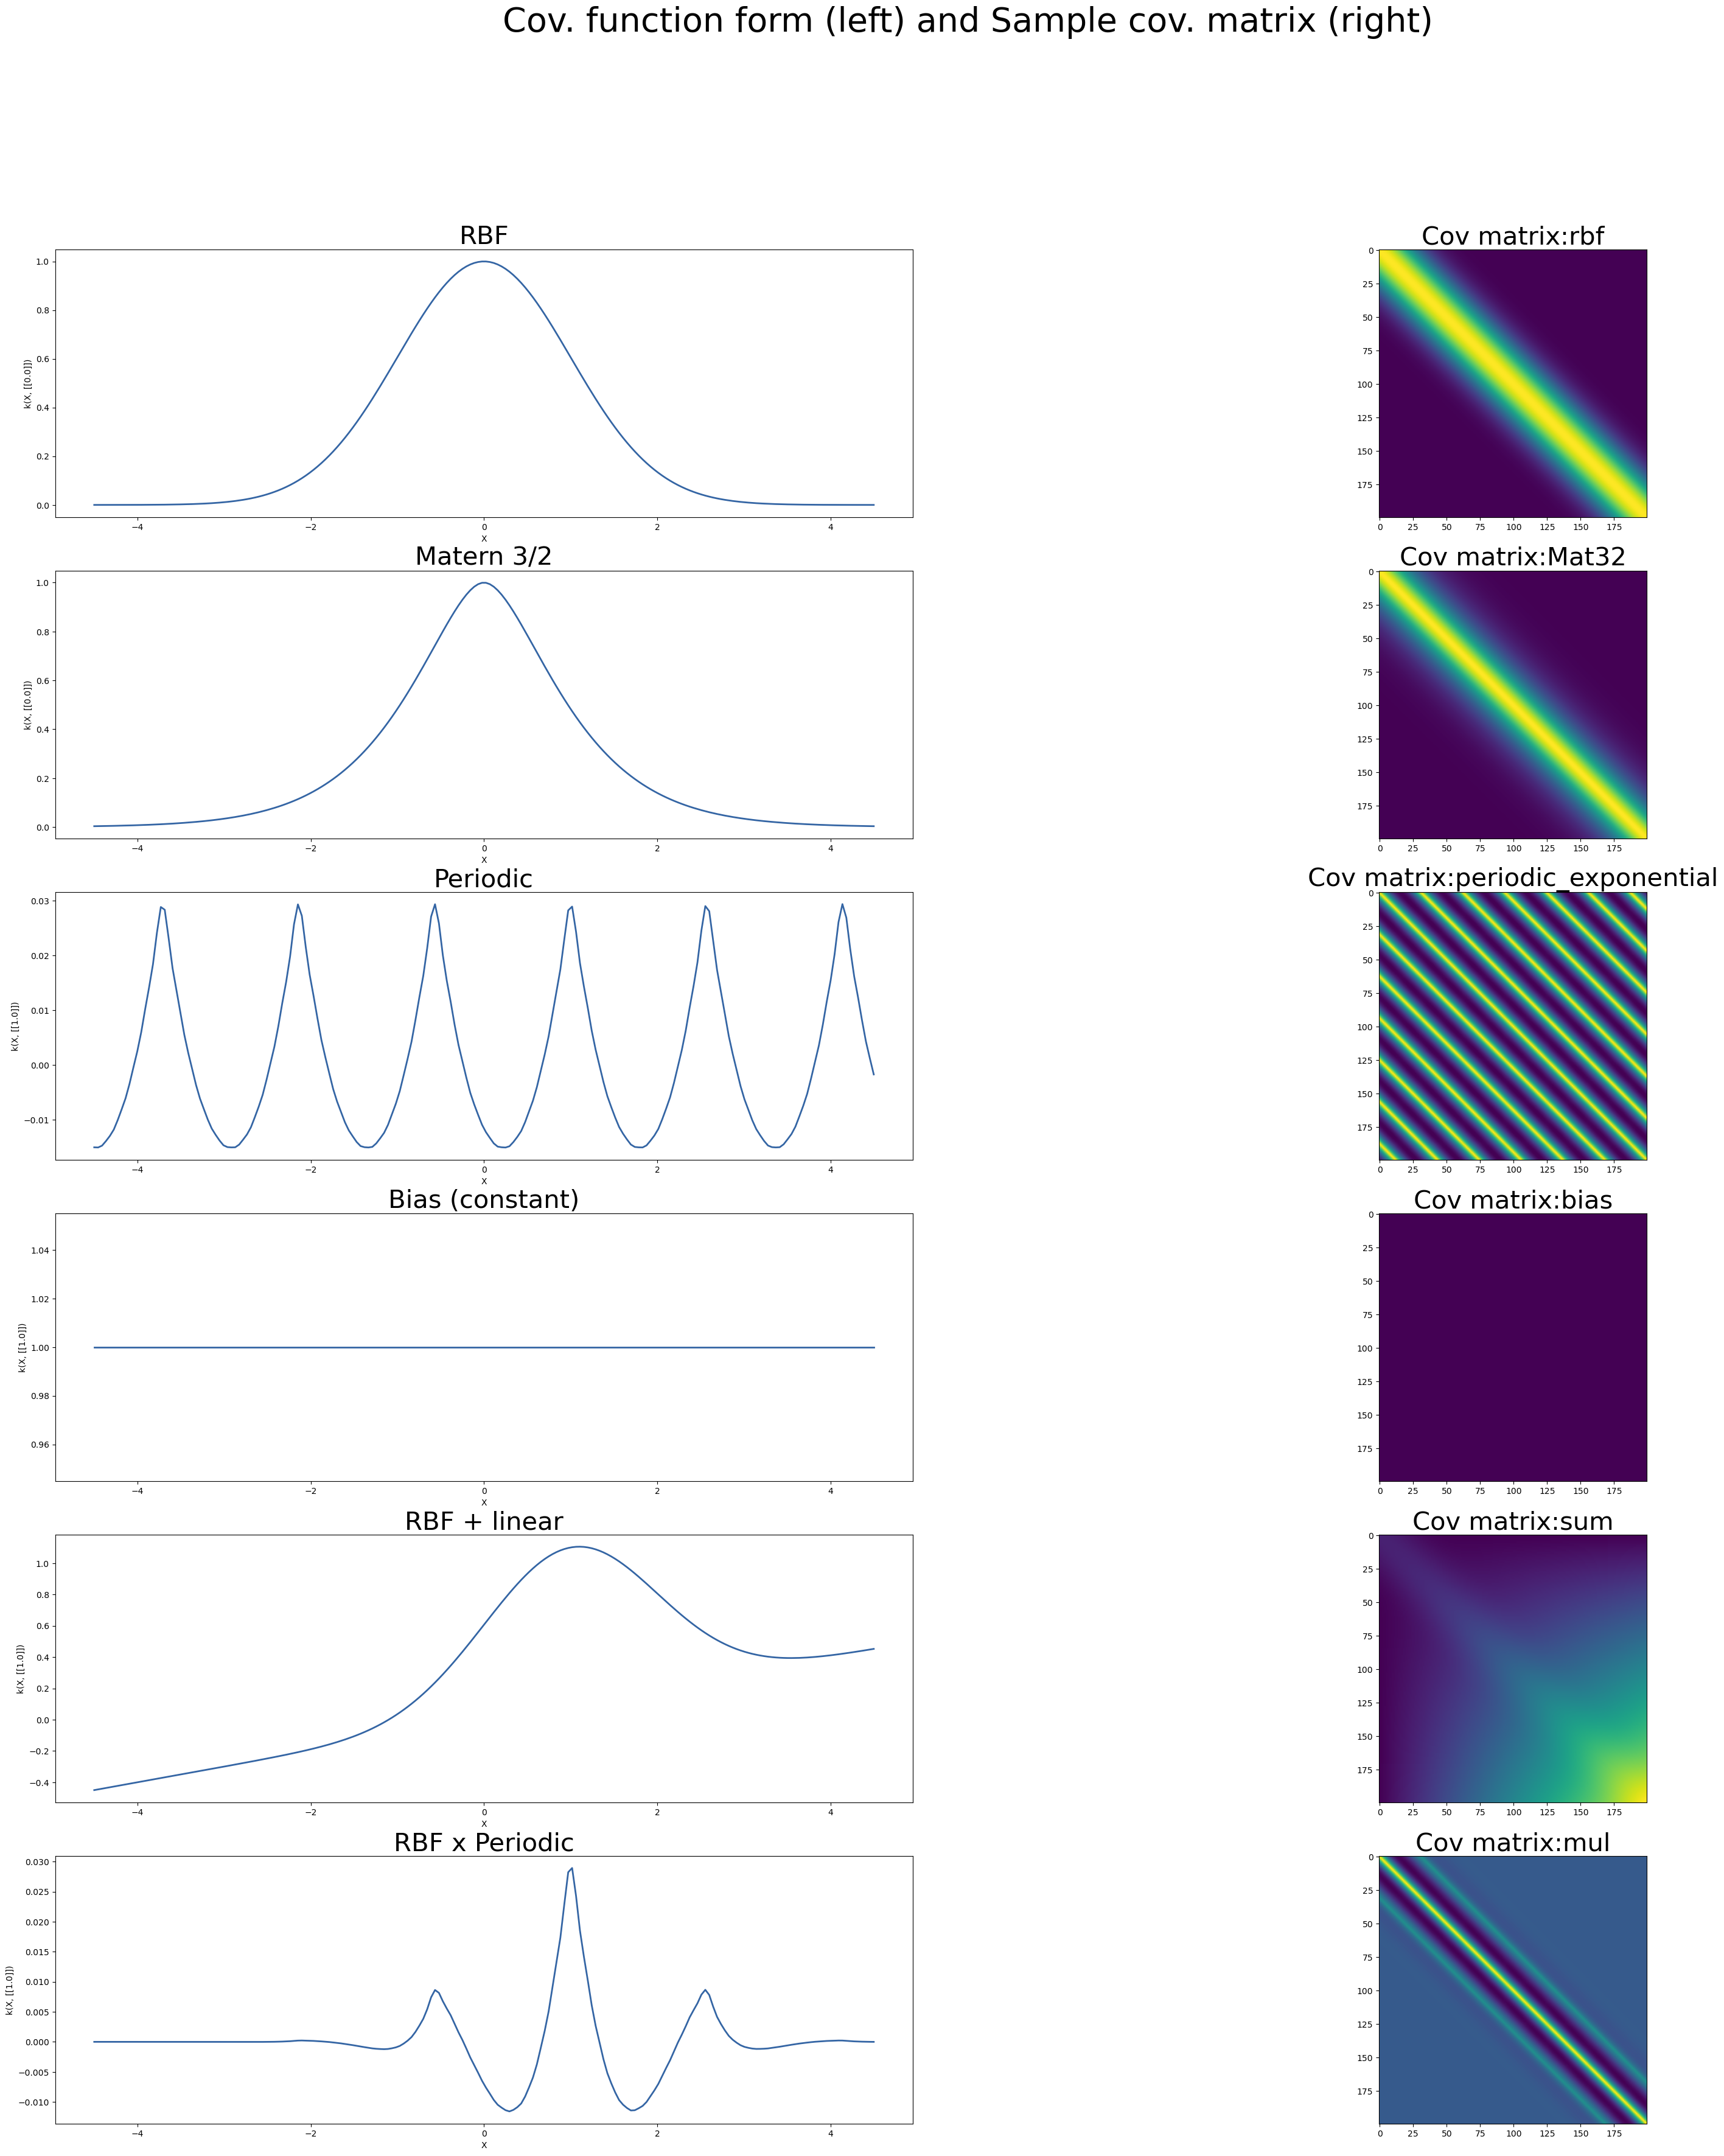

In [29]:
import GPy

Q=1
x_tmp = np.linspace(0,10,200)[:,None]

plt.figure(figsize=(40,40))
i=1
plt.subplot(6,2,i); i+=1
kern = GPy.kern.RBF(Q)
kern.plot(ax=plt.gca());  plt.gca().set_title('RBF', fontsize=30); 
plt.subplot(6,2,i); i+=1
plt.imshow(kern.K(x_tmp)); plt.gca().set_title('Cov matrix:' + kern.name, fontsize=30)
plt.subplot(6,2,i); i+=1

kern = GPy.kern.Matern32(Q)
kern.plot(ax=plt.gca()); plt.gca().set_title('Matern 3/2', fontsize=30);
plt.subplot(6,2,i); i+=1
plt.imshow(kern.K(x_tmp)); plt.gca().set_title('Cov matrix:' + kern.name, fontsize=30)
plt.subplot(6,2,i); i+=1

kern = GPy.kern.PeriodicExponential(Q,period=np.pi/2)
kern.plot(ax=plt.gca()); plt.gca().set_title('Periodic', fontsize=30);
plt.subplot(6,2,i); i+=1
plt.imshow(kern.K(x_tmp)); plt.gca().set_title('Cov matrix:' + kern.name, fontsize=30)
plt.subplot(6,2,i); i+=1

kern = GPy.kern.Bias(Q)
kern.plot(ax=plt.gca()); plt.gca().set_title('Bias (constant)', fontsize=30);
plt.subplot(6,2,i); i+=1
plt.imshow(kern.K(x_tmp)); plt.gca().set_title('Cov matrix:' + kern.name, fontsize=30)
plt.subplot(6,2,i); i+=1


# Incluso se pueden sumar kernels y obtener uno nuevo...
kern = GPy.kern.RBF(Q) + GPy.kern.Linear(Q,variances=0.1)
kern.plot(ax=plt.gca()); plt.gca().set_title('RBF + linear', fontsize=30)
plt.subplot(6,2,i); i+=1
plt.imshow(kern.K(x_tmp)); plt.gca().set_title('Cov matrix:' + kern.name, fontsize=30)
plt.subplot(6,2,i); i+=1


# ...or even multiply them!
kern = GPy.kern.RBF(Q) * GPy.kern.PeriodicExponential(Q,period=np.pi/2)
kern.plot(ax=plt.gca()); plt.gca().set_title('RBF x Periodic', fontsize=30)
plt.subplot(6,2,i); i+=1
plt.imshow(kern.K(x_tmp)); plt.gca().set_title('Cov matrix:' + kern.name, fontsize=30)

plt.suptitle('Cov. function form (left) and Sample cov. matrix (right)', fontsize=40);

## Ejemplo

Hacemos el ejemplo de regresión entre -5 y 5. Los puntos de datos de observació) se generan a partir de una distribución uniforme entre -5 y 5. Esto significa que cualquier valor de punto dentro del intervalo dado [-5, 5] es igualmente probable de ser seleccionado por la distribución uniforme. Las funciones se evaluarán en `n` puntos espaciados uniformemente entre -5 y 5. Hacemos esto para mostrar una función continua para la regresión en nuestra región de interés [-5, 5]. Este es un ejemplo simple para realizar regresión GP. Asume un Prior GP con media cero. El código toma prestado en gran medida de la [lectura de Dr. Nando de Freitas sobre procesos Gaussianos para regresión no lineal](https://youtu.be/4vGiHC35j9s).

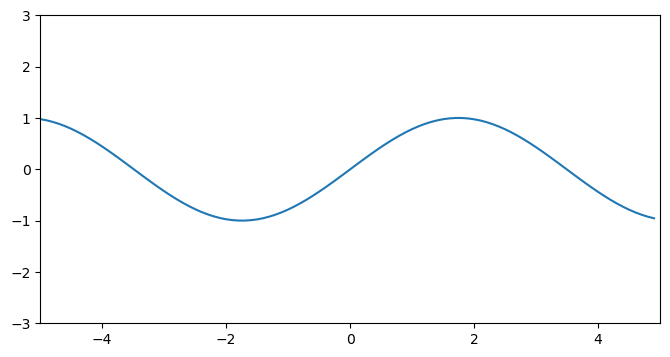

In [30]:
# Esta es la función verdadera y desconocida que intentamos aproximar
f = lambda x: np.sin(0.9*x).flatten()
#f = lambda x: (0.25*(x**2)).flatten()
x = np.arange(-5, 5, 0.1)
plt.figure(figsize=(8,4))
plt.plot(x, f(x))
plt.axis([-5, 5, -3, 3])
plt.show()

In [31]:
# Define the kernel
def kernel(a, b):
    kernelParameter_l = 0.1
    kernelParameter_sigma = 1.0
    sqdist = np.sum(a**2,axis=1).reshape(-1,1) + np.sum(b**2,1) - 2*np.dot(a, b.T)
    # np.sum( ,axis=1) means adding all elements columnly; .reshap(-1, 1) add one dimension to make (n,) become (n,1)
    return kernelParameter_sigma*np.exp(-.5 * (1/kernelParameter_l) * sqdist)

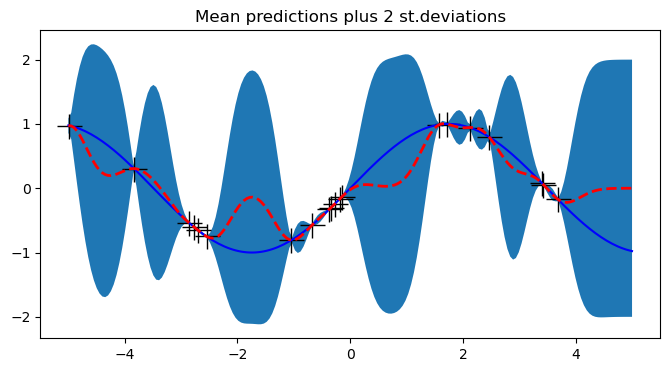

In [32]:
# Muestrear algunos puntos de entrada y versiones con ruido de la función evaluada en
# these points. 
N = 20         # número de puntos de observación existentes (puntos de entrenamiento).
n = 200        # número de puntos de prueba.
s = 0.00005    # noise variance.

X = np.random.uniform(-5, 5, size=(N,1))     # N training points 
y = f(X) + s*np.random.randn(N)

K = kernel(X, X)
L = np.linalg.cholesky(K + s*np.eye(N))     # line 1 

# points we're going to make predictions at.
Xtest = np.linspace(-5, 5, n).reshape(-1,1)

# compute the mean at our test points.
Lk = np.linalg.solve(L, kernel(X, Xtest))   # k_star = kernel(X, Xtest), calculating v := l\k_star
mu = np.dot(Lk.T, np.linalg.solve(L, y))    # \alpha = np.linalg.solve(L, y) 

# compute the variance at our test points.
K_ = kernel(Xtest, Xtest)                  # k(x_star, x_star)        
s2 = np.diag(K_) - np.sum(Lk**2, axis=0)   
s = np.sqrt(s2)

# PLOTS:
plt.figure(figsize=(8,4))
plt.plot(X, y, 'k+', ms=18)
plt.plot(Xtest, f(Xtest), 'b-')
plt.gca().fill_between(Xtest.flat, mu-2*s, mu+2*s)
plt.plot(Xtest, mu, 'r--', lw=2)
plt.title('Mean predictions plus 2 st.deviations')
plt.show()

<Figure size 640x480 with 0 Axes>

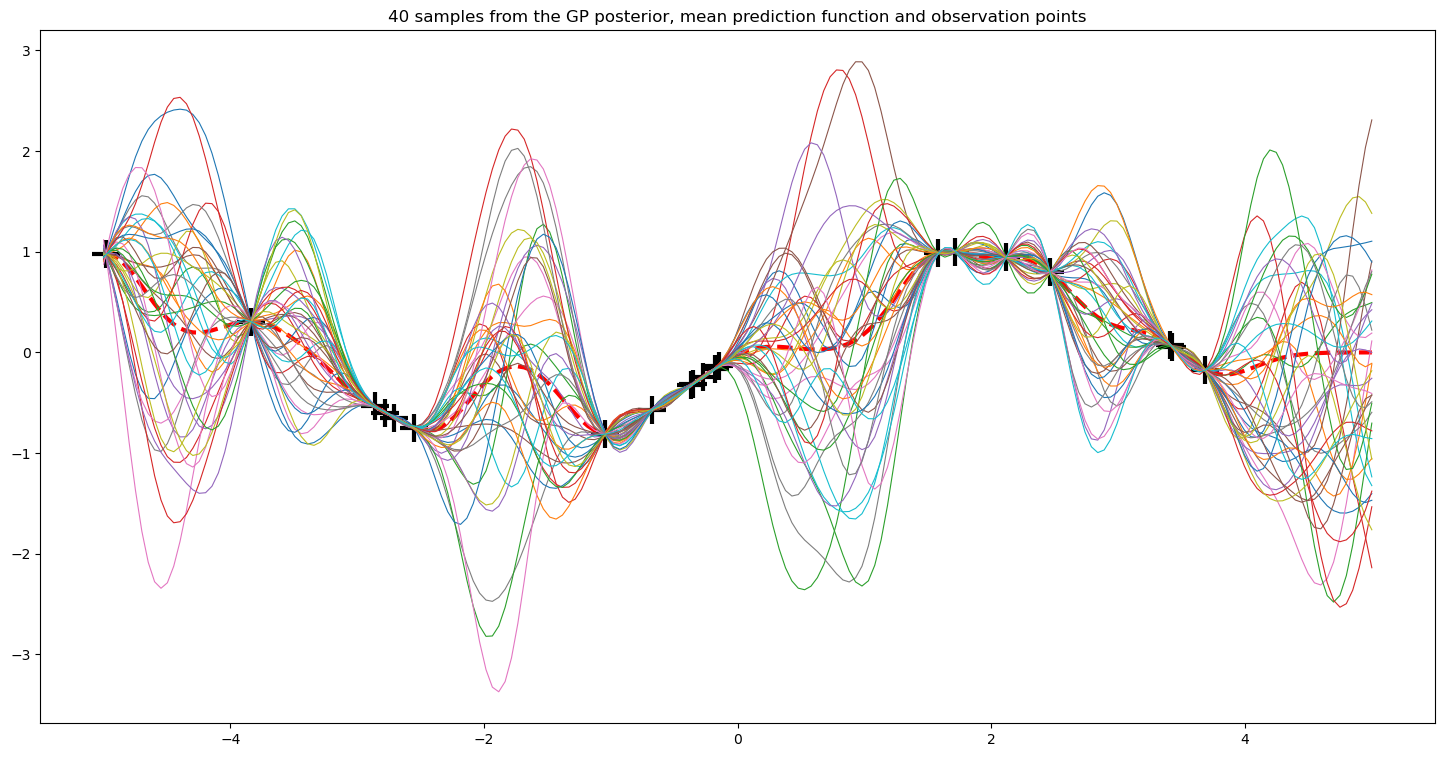

In [33]:
# tomar muestras de la distribución posterior en nuestros puntos de prueba.
L = np.linalg.cholesky(K_ + 1e-6*np.eye(n) - np.dot(Lk.T, Lk))
f_post = mu.reshape(-1,1) + np.dot(L, np.random.normal(size=(n,40)))  # size=(n, m); m indica cuántas muestras de la posterior
plt.figure(3)
plt.clf()
plt.figure(figsize=(18,9))
plt.plot(X, y, 'k+', markersize=20, markeredgewidth=3)
plt.plot(Xtest, mu, 'r--', linewidth=3)
plt.plot(Xtest, f_post, linewidth=0.8)
plt.title('40 samples from the GP posterior, mean prediction function and observation points');

Hemos graficado `m=40` muestras del posterior del Proceso Gaussiano junto con la función media para la predicción y los puntos de datos observados (conjunto de datos de entrenamiento). Es evidente que todas las funciones del posterior se colapsan en todos los puntos de observación.

## Full GP implementación

In [57]:
class CovFunctions(object):
    """
    A wrapper for covariance functions which is compatible with the GP class.
    """
    def __init__(self, covType, theta):
        self.covType = covType
        self.theta = theta
        if covType == 'linear':
            self.compute = self.linear
        elif covType == 'RBF':
            self.compute = self.RBF
    
    def set_theta(self, theta):

        self.theta = theta
    
    def get_theta(self):
        return self.theta
    
    def linear(self, x,x2=None):
        return cov_linear(x,x2,self.theta)
    
    def RBF(self, x, x2=None):
        return cov_RBF(x,x2,self.theta)


class GP(object):
    def __init__(self, X, Y, sigma2, covType, theta):
        self.X = X
        self.Y = Y
        self.N = self.X.shape[0]
        self.sigma2 = sigma2
        self.kern = CovFunctions(covType, theta)
        self.K = self.kern.compute(X)
        # Force computations
        self.update_stats()
    
    def get_params(self):
        return np.hstack((self.sigma2, self.kern.get_theta()))
    
    def set_params(self, params):
        self.sigma2 = params[0]
        self.kern.set_theta(params[1:])
    
    def update_stats(self):
        self.K = self.kern.compute(self.X)
        self.Kinv = np.linalg.inv(self.K+self.sigma2*np.eye(self.N))
        self.logdet = np.log(np.linalg.det(self.K+self.sigma2*np.eye(self.N)))
        self.KinvY = np.dot(self.Kinv, self.Y)
        # Equivalent to: np.trace(np.dot(self.Y, self.KinvY.T))
        self.YKinvY = (self.Y*self.KinvY).sum()
    
    def likelihood(self):
        """ 
        That's actually the logarithm of equation (3)
        Since logarithm is a convex function, maximum likelihood and maximum log likelihood wrt parameters
        would yield the same solutuion, but logarithm is better to manage mathematically and
        numerically.
        """
        return -0.5*(self.N*np.log(2*np.pi) + self.logdet + self.YKinvY)
    
    def posterior(self, x_star):
        """
        Implements equation (4)
        """
        self.update_stats()
        K_starstar = self.kern.compute(x_star, x_star)
        K_star = self.kern.compute(self.X, x_star)
        KinvK_star = np.dot(self.Kinv, K_star)
        mu_pred = np.dot(KinvK_star.T, self.Y)
        K_pred = K_starstar - np.dot(KinvK_star.T, K_star)
        return mu_pred, K_pred
    
    def objective(self,params):
        self.set_params(params)
        self.update_stats()
        return -self.likelihood()
        
def plot_fit(x,y,mu,var):
    """
    Plot the fit of a GP
    """
    plt.plot(x,y, 'k-o',label='true')
    plt.plot(x,mu, 'b-<',label='predicted')
    plt.plot(x, mu+2*np.sqrt(var), 'r--',label='var')
    plt.plot(x, mu-2*np.sqrt(var), 'r--')
    plt.legend()

Crearemos algunos datos de muestra en 1D a partir de un Proceso Gaussiano (GP) con covarianza RBF y una longitud de escala = 0.85. A continuación, normalizamos los datos y reservamos algunos para pruebas. Luego, graficamos los datos.


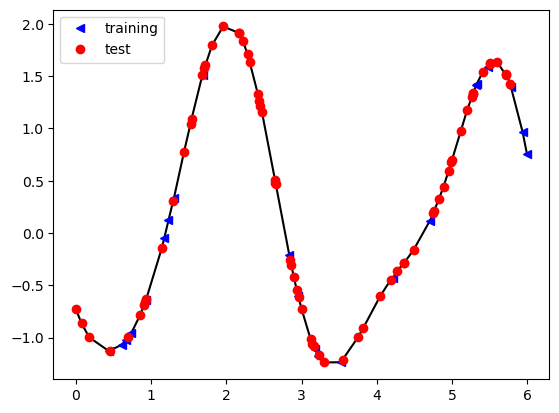

In [58]:
N=22 # número de puntos de entrenamiento
Nstar = 70 # número de puntos de prueba

# create toy data
X = np.sort(np.random.rand(N+Nstar, 1) * 6 , axis=0)



K_rbf = cov_RBF(X,X,theta=np.array([1,0.85]))
mu=np.zeros((1,K_rbf.shape[0]))[0,:]
jitter = 1e-5*np.eye(K_rbf.shape[0])
Y = np.random.multivariate_normal(mean=mu, cov=K_rbf+jitter)[:,None]
#Y = np.sin(X*2) + np.random.randn(*X.shape) * 0.008

# split data into training and test set
perm = np.random.permutation(X.shape[0])
Xtr = X[np.sort(perm[0:N],axis=0),:]
Ytr = Y[np.sort(perm[0:N],axis=0),]
X_star = X[np.sort(perm[N:N+Nstar],axis=0),:]
Y_star = Y[np.sort(perm[N:N+Nstar],axis=0),:]

# Normalizar los datos para que tengan media 0 y desviación estándar 1
Ymean = Ytr.mean()
Ystd = Ytr.std()
Ytr-=Ymean
Ytr/=Ystd
Y_star -= Ymean
Y_star /= Ystd

# plot data
plt.plot(X,(Y-Ymean)/Ystd, 'k-')
plt.plot(Xtr,Ytr, 'b<',label='training')
plt.plot(X_star,Y_star, 'ro',label='test')
plt.legend();

Ahora definiremos dos modelos de Proceso Gaussiano (GP), uno con una función de covarianza lineal y otro con una función de covarianza RBF. Los utilizaremos para predecir los datos de entrenamiento y de prueba.


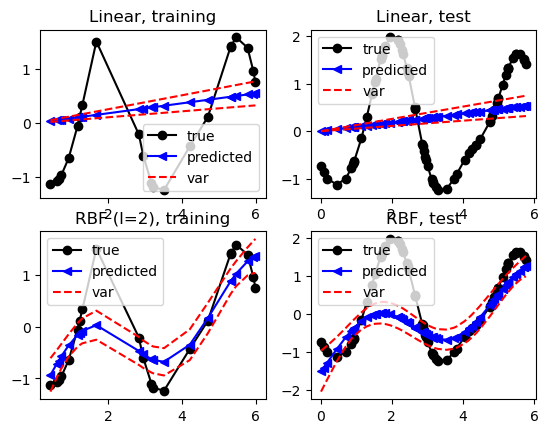

In [59]:
# Define GP models with initial parameters
g_lin = GP(Xtr, Ytr, 0.1, 'linear', 2)
g_rbf = GP(Xtr, Ytr, 0.1, 'RBF', np.array([1,2]))

# Obtener la posterior de los dos GP sobre los datos de *entrenamiento*
mu_lin_tr,var_lin_tr = g_lin.posterior(Xtr)
mu_rbf_tr,var_rbf_tr = g_rbf.posterior(Xtr)

# Obtener la posterior de los dos GP sobre los datos de *prueba*
mu_lin_star,var_lin_star = g_lin.posterior(X_star)
mu_rbf_star,var_rbf_star = g_rbf.posterior(X_star)

# Graficar el ajuste de los dos GP sobre los datos de entrenamiento y de prueba
ax=plt.subplot(2, 2, 1); ax.set_aspect('auto')
plot_fit(Xtr, Ytr, mu_lin_tr, np.diag(var_lin_tr)[:,None])
plt.gca().set_title('Linear, training')

ax=plt.subplot(2, 2, 2); ax.set_aspect('auto')
plot_fit(X_star, Y_star, mu_lin_star, np.diag(var_lin_star)[:,None])
plt.gca().set_title('Linear, test')

ax=plt.subplot(2, 2, 3); ax.set_aspect('auto')
plot_fit(Xtr, Ytr, mu_rbf_tr, np.diag(var_rbf_tr)[:,None])
plt.gca().set_title('RBF (l=' +  str(g_rbf.kern.get_theta()[1]) + '), training')

ax=plt.subplot(2, 2, 4); ax.set_aspect('auto')
plot_fit(X_star, Y_star, mu_rbf_star, np.diag(var_rbf_star)[:,None])
plt.gca().set_title('RBF, test');

Recuerda que el valor verdadero que genera los datos es 0.85, pero esperaríamos encontrarlo como el mejor solo si tuviéramos datos infinitos. De lo contrario, también se espera encontrar un valor cercano.

En el siguiente gráfico mostramos el ajuste para cada longitud de escala y la verosimilitud lograda por cada una.


In [ ]:
import matplotlib.mlab as mlab


from scipy.stats import multivariate_normal


import seaborn as sns

from sklearn.metrics import mean_squared_error as mse
from scipy.stats import normaltest
from sklearn.datasets import make_friedman2

from sklearn.gaussian_process.kernels import DotProduct, WhiteKernel
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
import random


import sklearn

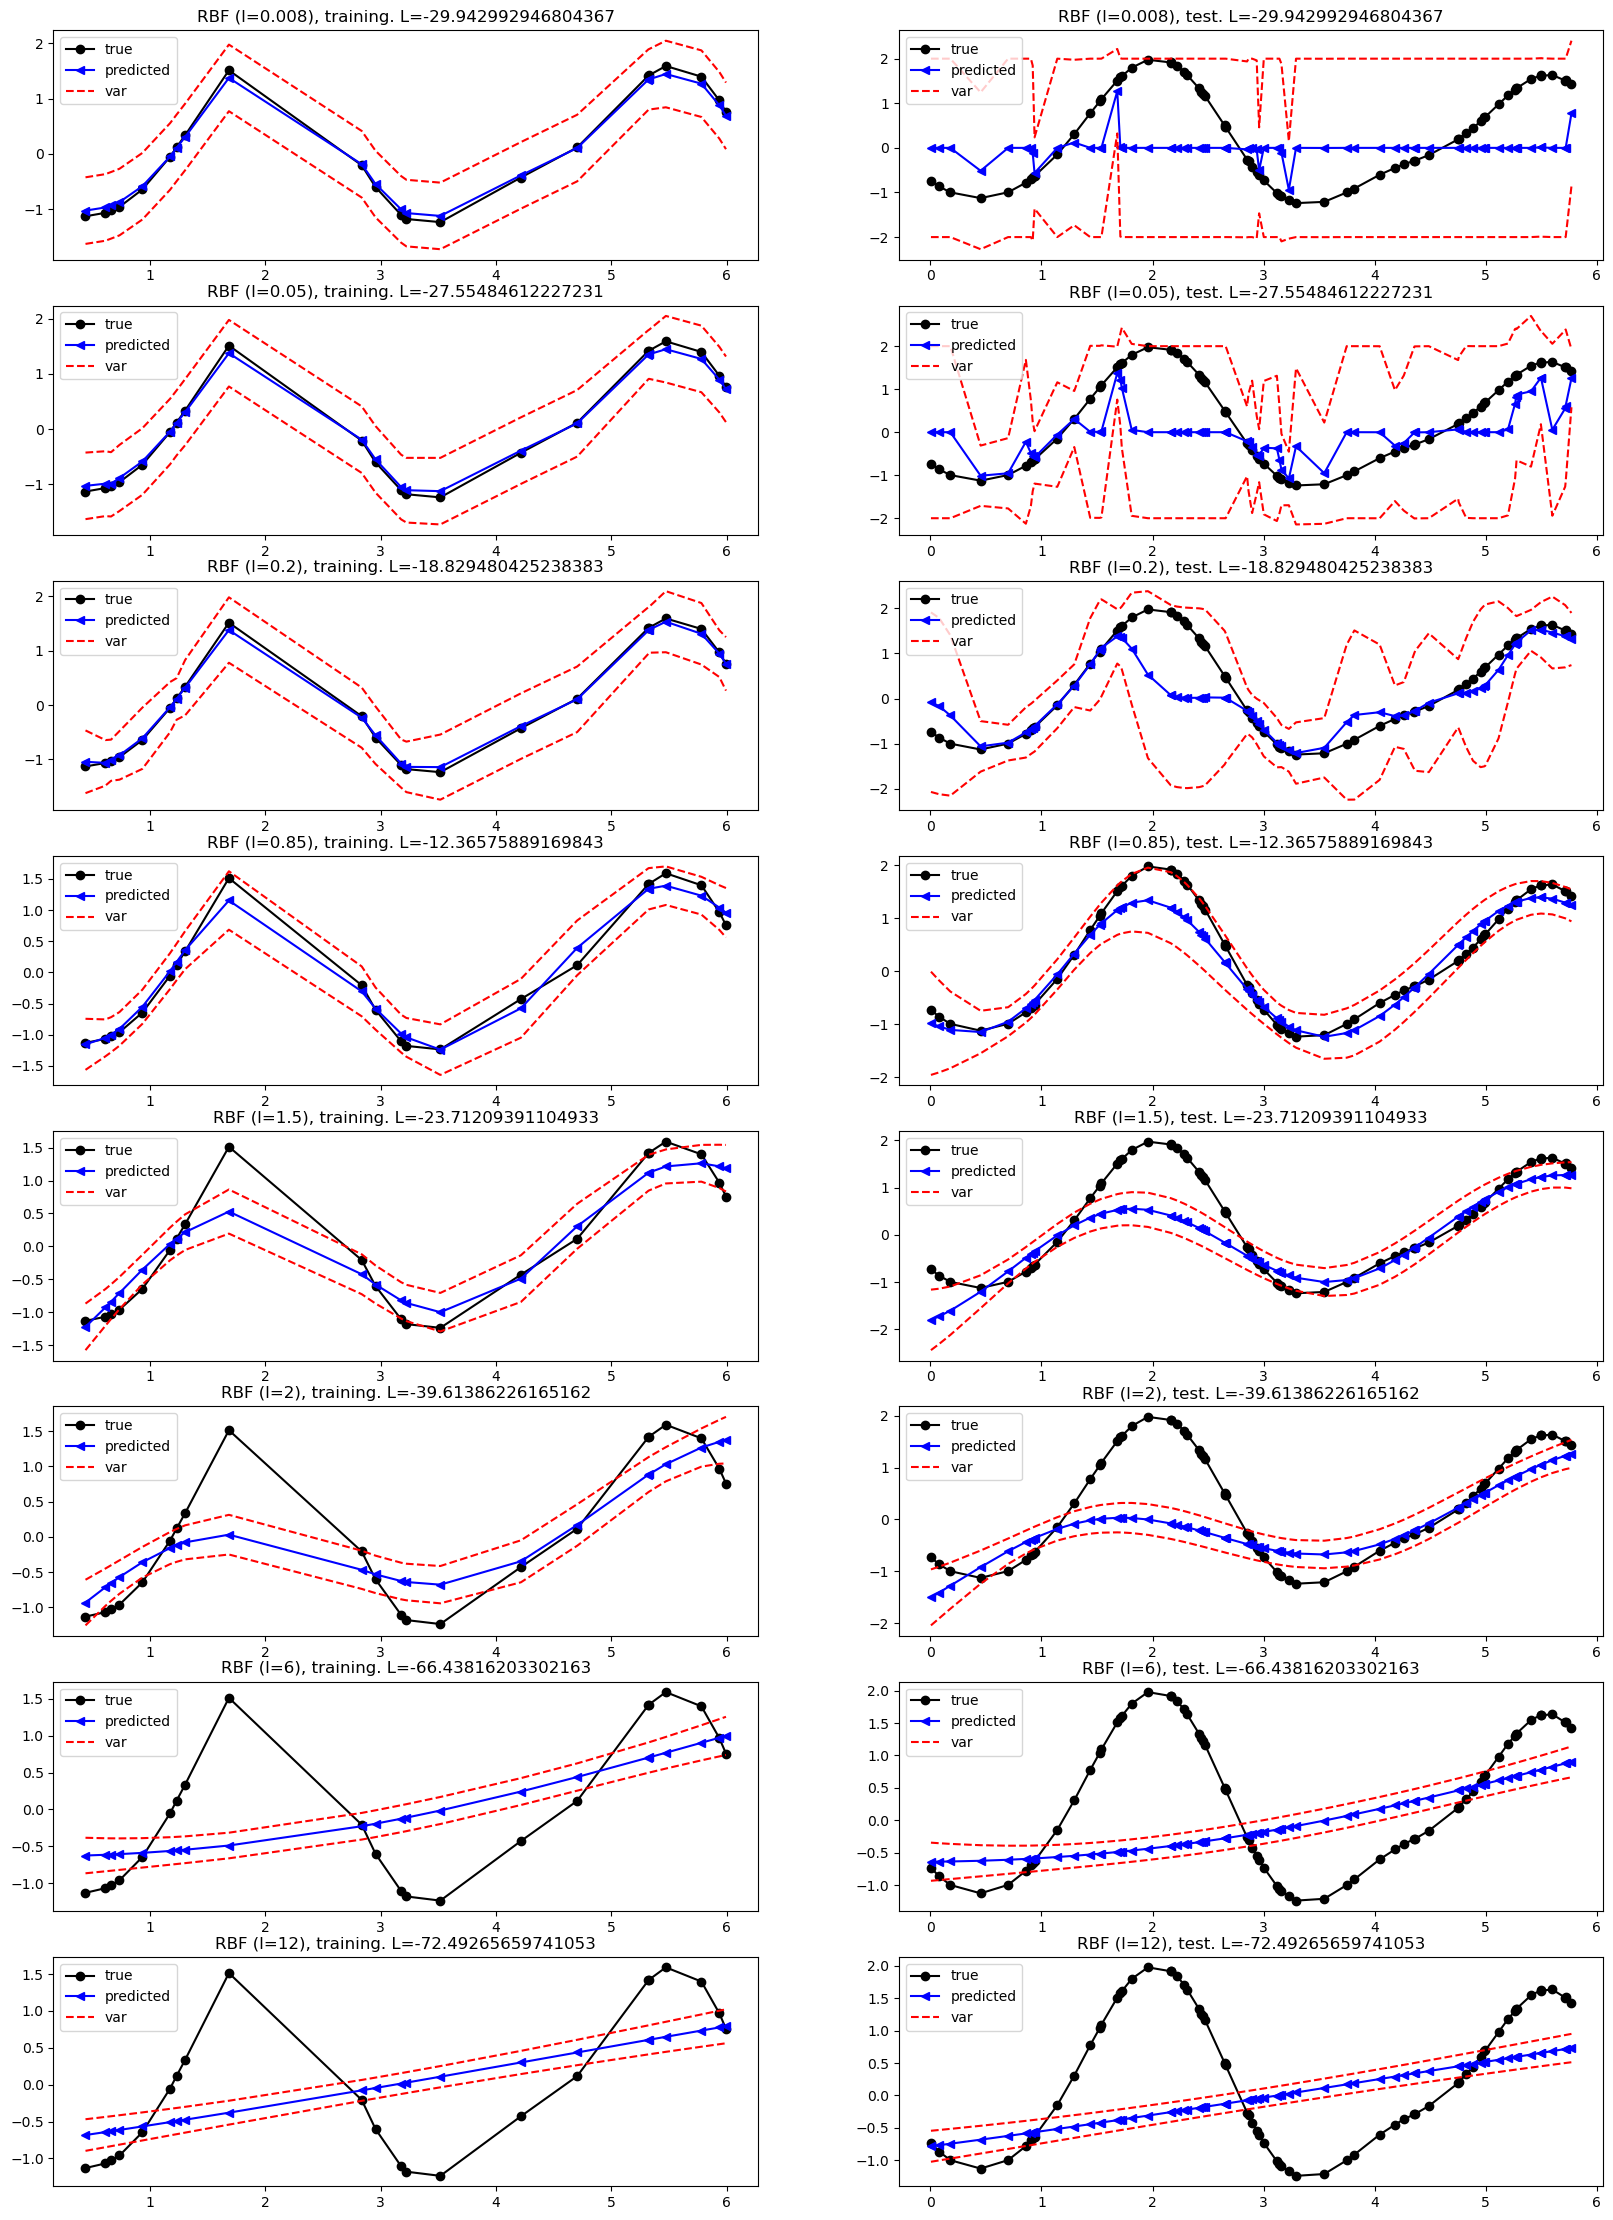

In [71]:
from matplotlib.pyplot import figure

f=figure(figsize=(20,28)) 
i = 1
# Following array holds different lengthscales to test one by one
test_l=[0.008, 0.05, 0.2, 0.85, 1.5, 2, 6, 12]
for l in test_l:
    g_rbf = GP(Xtr, Ytr, 0.1, 'RBF', np.array([1,l]))
    mu_rbf_tr,var_rbf_tr = g_rbf.posterior(Xtr)
    mu_rbf_star,var_rbf_star = g_rbf.posterior(X_star)

    ax=plt.subplot(len(test_l), 2,i); ax.set_aspect('auto')
    plot_fit(Xtr, Ytr, mu_rbf_tr, np.diag(var_rbf_tr)[:,None])
    ll = g_rbf.likelihood()
    plt.gca().set_title('RBF (l=' +  str(g_rbf.kern.get_theta()[1]) + '), training. L=' + str(ll) )

    ax=plt.subplot(len(test_l), 2, i+1); ax.set_aspect('auto')
    plot_fit(X_star, Y_star, mu_rbf_star, np.diag(var_rbf_star)[:,None])
    ll = g_rbf.likelihood()
    plt.gca().set_title('RBF (l=' +  str(g_rbf.kern.get_theta()[1]) + '), test. L=' + str(ll) )
    i+=2;

Vemos que las longitudes de escala muy cortas generan funciones más "onduladas", que son capaces de interpolar perfectamente entre los puntos de entrenamiento. Sin embargo, un modelo sobreajustado de este tipo tiende a estar más "sorprendido" por cualquier cosa que no sea exactamente los mismos datos de entrenamiento... por lo tanto, tiene un mal desempeño en el conjunto de prueba.

Por otro lado, las longitudes de escala grandes generan funciones muy planas, que en el límite se parecen a una función lineal y subajustan los datos.

Entonces, ¿cómo encontramos automáticamente la longitud de escala correcta?

El enfoque más adecuado para seleccionar el parámetro correcto no es una verificación visual ni probar el error en los datos de entrenamiento/conjunto de validación. En cambio, queremos observar la verosimilitud, que nos indica cuál es la probabilidad de que el modelo específico (con longitud de escala l) haya generado los datos.

Para mostrar esto, probaremos nuevamente diferentes configuraciones para la longitud de escala del GP-RBF, pero esta vez haremos un seguimiento de la verosimilitud y también del error de entrenamiento/prueba.

Primero, crea algunas funciones auxiliares:


In [72]:
# Root mean squared error
def rmse(pred, truth):
    pred = pred.flatten()
    truth = truth.flatten()
    return np.sqrt(np.mean((pred-truth)**2))

# Make data 0 mean and 1 std.
def standardize(x):
    return (x-x.mean())/x.std()

In [73]:
test_l=np.linspace(0.01,5, 100)
ll = []
err_tr = []
err_test = []
for l in test_l:
    g_rbf = GP(Xtr, Ytr, 0.1, 'RBF', np.array([1,l]))
    g_rbf.update_stats()
    ll.append(g_rbf.likelihood())
    mu_rbf_tr,var_rbf_tr = g_rbf.posterior(Xtr)
    err_tr.append(rmse(mu_rbf_tr, Ytr))
    mu_rbf_star,var_rbf_star = g_rbf.posterior(X_star)
    err_test.append(rmse(mu_rbf_star, Y_star))
ll = standardize(np.array(ll))
err_tr = standardize(np.array(err_tr))
err_test = standardize(np.array(err_test))

Best lengthscale according to likelihood 0.6652525252525253
Best lengthscale according to training error: 0.26202020202020204
Best lengthscale according to test error    : 0.614848484848485


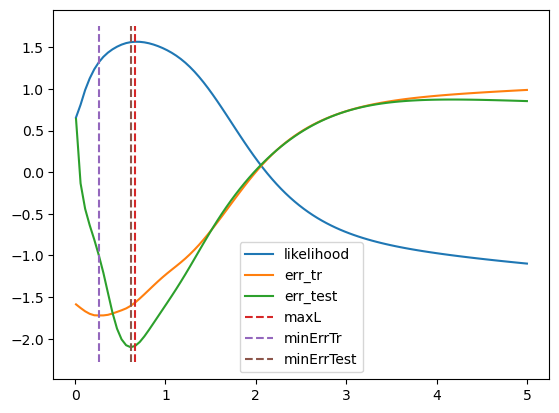

In [74]:
max_ll, argmax_ll = np.max(ll), np.argmax(ll)
min_err_tr, argmin_err_tr = np.min(err_tr), np.argmin(err_tr)
min_err_test, argmin_err_test = np.min(err_test), np.argmin(err_test)

plt.plot(test_l, ll,label='likelihood')
plt.plot(test_l, err_tr,label='err_tr')
plt.plot(test_l, err_test,label='err_test')
tmp_x = np.ones(test_l.shape[0])
ylim=plt.gca().get_ylim()
tmp_y = np.linspace(ylim[0],ylim[1], tmp_x.shape[0])
plt.plot(tmp_x*test_l[argmax_ll], tmp_y,'--', label='maxL')
plt.plot(tmp_x*test_l[argmin_err_tr], tmp_y,'--', label='minErrTr')
plt.plot(tmp_x*test_l[argmin_err_test], tmp_y,'--', label='minErrTest')

plt.legend()
print(f"Best lengthscale according to likelihood {str(test_l[argmax_ll])}")
print(f"Best lengthscale according to training error: {str(test_l[argmin_err_tr])}")
print(f"Best lengthscale according to test error    : {str(test_l[argmin_err_test])}")

El hecho de que la mejor longitud de escala (según la verosimilitud) no sea necesariamente la que nos da el menor error de entrenamiento es una buena propiedad, es decir, el modelo evita el sobreajuste.

La longitud de escala elegida también está bastante cerca de la longitud verdadera. Realizar el experimento con más datos revelará una coincidencia aún más cercana (ten en cuenta que los problemas numéricos debido a la codificación simple aquí podrían causar problemas en los cálculos).

Para optimizar correctamente el kernel, queremos evitar una búsqueda exhaustiva del parámetro correcto, especialmente dado que también hay otros parámetros que antes consideramos fijos.

La forma de optimizar el Proceso Gaussiano (GP) según la máxima verosimilitud es utilizando la información del gradiente. Luego, al proporcionar las funciones de los gradientes y la función del objetivo (ya implementada en GP.objective) a un optimizador de gradiente, obtendrás automáticamente el resultado. Consulta la función *optimize* de SciPy.

Para ahorrar algo de tiempo y esfuerzo, demostraremos la optimización con GPy [http://github.com/SheffieldML/GPy], un paquete de software de GP escrito en Python.

In [75]:
Q = Xtr.shape[1]
k = GPy.kern.RBF(Q)
m = GPy.models.GPRegression(X=Xtr, Y=Ytr, kernel=k)


Name : GP regression
Objective : 27.757946074726643
Number of Parameters : 3
Number of Optimization Parameters : 3
Updates : True
Parameters:
  GP_regression.           |  value  |  constraints  |  priors
  rbf.variance             |    1.0  |      +ve      |        
  rbf.lengthscale          |    1.0  |      +ve      |        
  Gaussian_noise.variance  |    1.0  |      +ve      |        


{'dataplot': [<matplotlib.collections.PathCollection at 0x73675d16c760>],
 'gpmean': [[<matplotlib.lines.Line2D at 0x73675d16ceb0>]],
 'gpconfidence': [<matplotlib.collections.FillBetweenPolyCollection at 0x73675d16ce50>]}

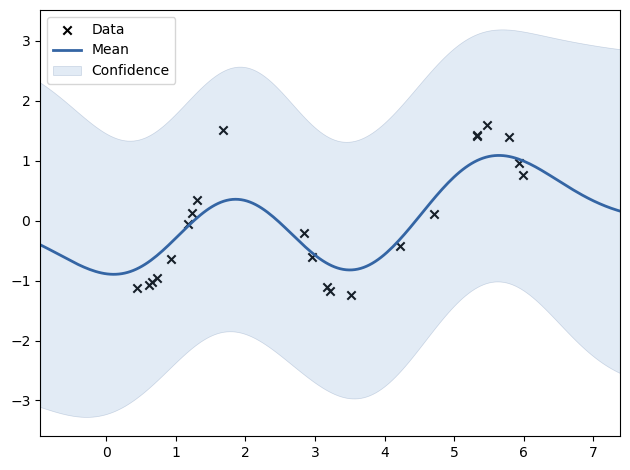

In [76]:
print (m)
m.plot()

Optimiza utilizando el método del gradiente. Observa cómo la longitud de escala optimizada está cerca de la que encontramos antes mediante búsqueda en rejilla y aún más cerca de la verdadera.


In [77]:
m.optimize(messages=1)

Running L-BFGS-B (Scipy implementation) Code:
  runtime   i      f              |g|        
    00s01  0002   2.255556e+01   3.140543e+01 
    00s09  0008   8.737759e+06   3.466496e+13 
    00s11  0015  -2.588187e+01   6.947934e+00 
    00s13  0023  -2.607996e+01   4.208194e-11 
Runtime:     00s13
Optimization status: Converged




Name : GP regression
Objective : -26.07996205909806
Number of Parameters : 3
Number of Optimization Parameters : 3
Updates : True
Parameters:
  GP_regression.           |                   value  |  constraints  |  priors
  rbf.variance             |      3.3643776903467857  |      +ve      |        
  rbf.lengthscale          |      0.8702751546025165  |      +ve      |        
  Gaussian_noise.variance  |  2.8520515842175454e-05  |      +ve      |        


{'dataplot': [<matplotlib.collections.PathCollection at 0x73675cdc29b0>],
 'gpmean': [[<matplotlib.lines.Line2D at 0x73675cdc3100>]],
 'gpconfidence': [<matplotlib.collections.FillBetweenPolyCollection at 0x73675cdc30a0>]}

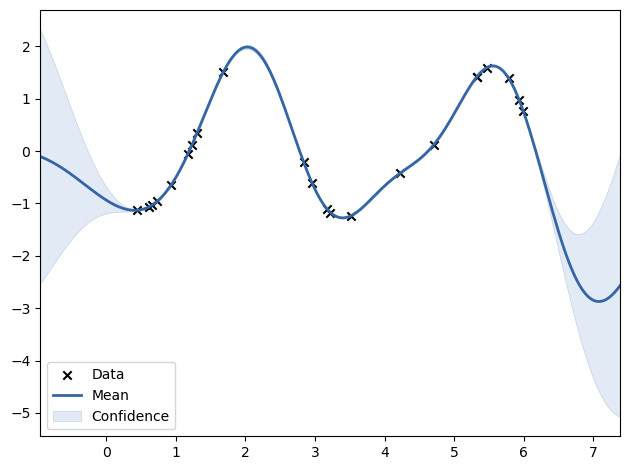

In [78]:
print(m)
m.plot()

Predecir nuevos datos

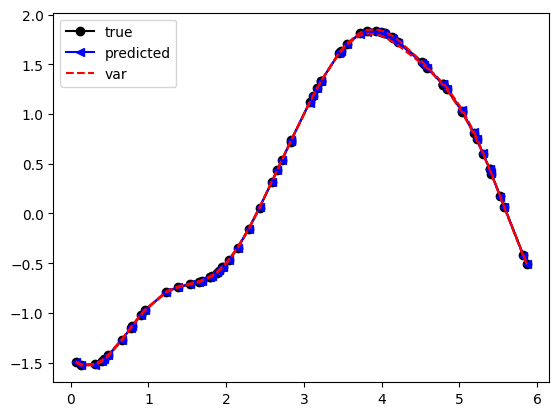

In [87]:
mu,var = m.predict(X_star)
plot_fit(X_star, Y_star, mu, var)

## Ejemplo

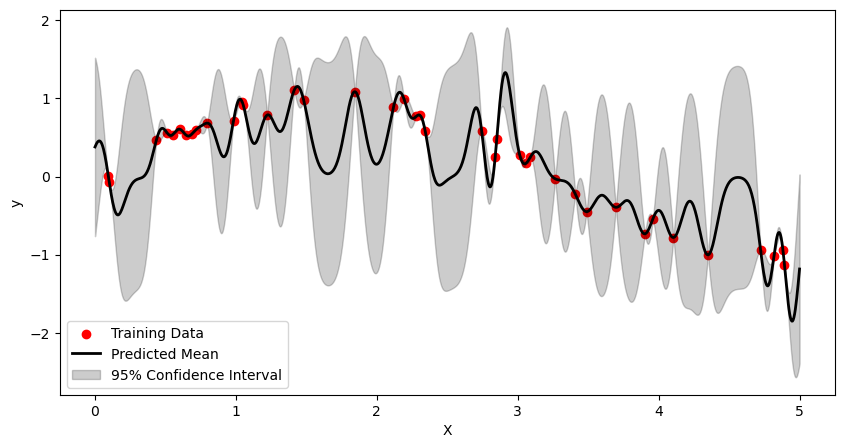

In [80]:
# Generate sample data
np.random.seed(0)
X = np.sort(5 * np.random.rand(80, 1), axis=0)
y = np.sin(X).ravel()

# Add noise to the data
y += 0.1 * np.random.randn(80)

# Define the kernel (RBF kernel)
kernel = 1.0 * kernels.RBF(length_scale=1.0)

# Create a Gaussian Process Regressor with the defined kernel
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)

# Dividir los datos en conjuntos de entrenamiento y prueba
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
	X, y, test_size=0.5, random_state=0)

# Ajustar el modelo de Proceso Gaussiano a los datos de entrenamiento
gp.fit(X_train, y_train)

# Make predictions on the test data
y_pred, sigma = gp.predict(X_test, return_std=True)

# Visualize the results
x = np.linspace(0, 5, 1000)[:, np.newaxis]
y_mean, y_cov = gp.predict(x, return_cov=True)

plt.figure(figsize=(10, 5))
plt.scatter(X_train, y_train, c='r', label='Training Data')
plt.plot(x, y_mean, 'k', lw=2, zorder=9, label='Predicted Mean')
plt.fill_between(x[:, 0], y_mean - 1.96 * np.sqrt(np.diag(y_cov)), y_mean + 1.96 *
				np.sqrt(np.diag(y_cov)), alpha=0.2, color='k', label='95% Confidence Interval')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.show()

## Ejemplo

In [81]:
X = np.linspace(start=0, stop=10, num=1_000).reshape(-1, 1)
y = np.squeeze(X * np.sin(X))

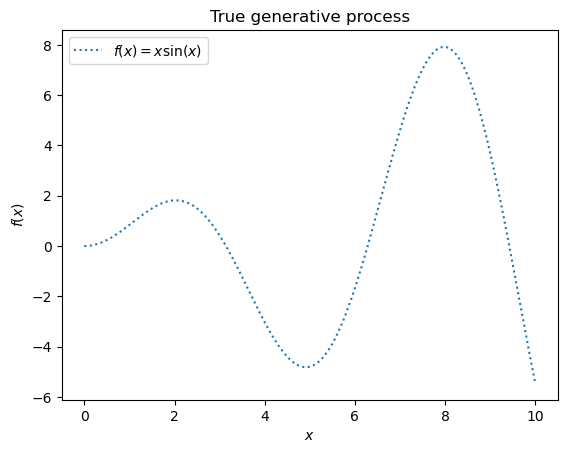

In [82]:
plt.plot(X, y, label=r"$f(x) = x \sin(x)$", linestyle="dotted")
plt.legend()
plt.xlabel("$x$")
plt.ylabel("$f(x)$")
_ = plt.title("True generative process")

### Example with noise-free target¶

In [83]:
rng = np.random.RandomState(1)
training_indices = rng.choice(np.arange(y.size), size=6, replace=False)
X_train, y_train = X[training_indices], y[training_indices]

In [84]:

kernel = 1 * kernels.RBF(length_scale=1.0, length_scale_bounds=(1e-2, 1e2))
gaussian_process = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=9)
gaussian_process.fit(X_train, y_train)
gaussian_process.kernel_

5.02**2 * RBF(length_scale=1.43)

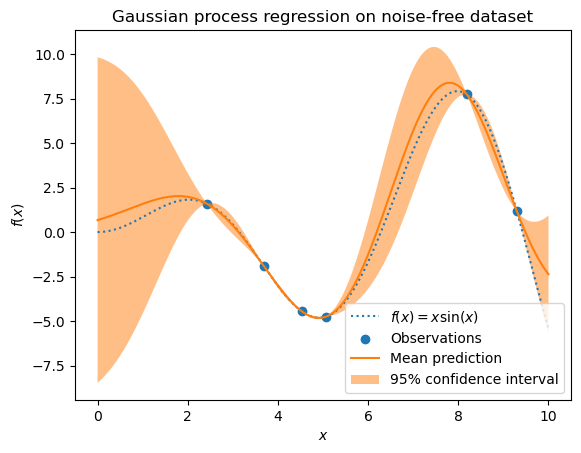

In [85]:
mean_prediction, std_prediction = gaussian_process.predict(X, return_std=True)

plt.plot(X, y, label=r"$f(x) = x \sin(x)$", linestyle="dotted")
plt.scatter(X_train, y_train, label="Observations")
plt.plot(X, mean_prediction, label="Mean prediction")
plt.fill_between(
    X.ravel(),
    mean_prediction - 1.96 * std_prediction,
    mean_prediction + 1.96 * std_prediction,
    alpha=0.5,
    label=r"95% confidence interval",
)
plt.legend()
plt.xlabel("$x$")
plt.ylabel("$f(x)$")
_ = plt.title("Gaussian process regression on noise-free dataset")

### Example with noisy targets¶


In [86]:
noise_std = 0.75
y_train_noisy = y_train + rng.normal(loc=0.0, scale=noise_std, size=y_train.shape)

In [87]:
gaussian_process = GaussianProcessRegressor(kernel=kernel, alpha=noise_std**2, n_restarts_optimizer=9)
gaussian_process.fit(X_train, y_train_noisy)
mean_prediction, std_prediction = gaussian_process.predict(X, return_std=True)

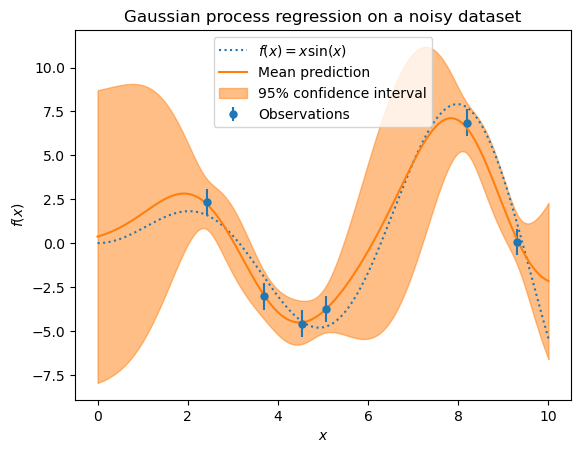

In [88]:
plt.plot(X, y, label=r"$f(x) = x \sin(x)$", linestyle="dotted")
plt.errorbar(
    X_train,
    y_train_noisy,
    noise_std,
    linestyle="None",
    color="tab:blue",
    marker=".",
    markersize=10,
    label="Observations",
)
plt.plot(X, mean_prediction, label="Mean prediction")
plt.fill_between(
    X.ravel(),
    mean_prediction - 1.96 * std_prediction,
    mean_prediction + 1.96 * std_prediction,
    color="tab:orange",
    alpha=0.5,
    label=r"95% confidence interval",
)
plt.legend()
plt.xlabel("$x$")
plt.ylabel("$f(x)$")
_ = plt.title("Gaussian process regression on a noisy dataset")

### Ejemplo con dos covariables

| Paso           | Descripción breve                                                                                                                                                                     |
| -------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Datos**      | Creamos 80 puntos $(x_1,x_2)$ aleatorios en $[0,1]^2$ y calculamos $y = \sin(4x_1)+\cos(4x_2)+\varepsilon$.                                                                           |
| **Kernel**     | `ConstantKernel` controla la varianza total; `RBF` introduce correlación suave con longitudes de escala *diferentes* para cada covariable; `WhiteKernel` modela el ruido de medición. |
| **Ajuste**     | `GaussianProcessRegressor` aprende hiperparámetros (longitudes de escala, varianza, ruido) maximizando la log-marginal.                                                               |
| **Predicción** | Evaluamos la media $\mu_\ast$ y la desviación estándar $\sigma_\ast$ en una malla 40 × 40 para visualizar la superficie posterior.                                                    |
| **Gráfica**    | La malla azulada representa $\mu_\ast(x_1,x_2)$; los puntos indican los datos. En tres dimensiones percibes cómo el GP interpola y suaviza los valores observados.                    |


In [89]:

# 2. Datos sintéticos ---------------------------------------------------------
rng = np.random.RandomState(42)
n = 80                                # número de observaciones
X = rng.uniform(0, 1, (n, 2))         # dos covariables: x1, x2  ∈ [0,1]

def f_true(x):
    """Función 'real' (desconocida) que queremos aprender."""
    return np.sin(4 * x[:, 0]) + np.cos(4 * x[:, 1])

y = f_true(X) + 0.1 * rng.randn(n)    # añadimos ruido gaussiano ε ~ N(0, 0.1²)


In [91]:
# 3. Definición del kernel -----------------------------------------------------
kernel = kernels.RBF(length_scale=[0.2, 0.2], length_scale_bounds=(1e-2, 1e1)) 

gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)

gp.fit(X, y)                    

GaussianProcessRegressor(kernel=RBF(length_scale=[0.2, 0.2]),
                         n_restarts_optimizer=10)

In [92]:
# 5. Malla de predicción -------------------------------------------------------
xx = np.linspace(0, 1, 40)
yy = np.linspace(0, 1, 40)
Xg1, Xg2 = np.meshgrid(xx, yy)
X_grid = np.column_stack([Xg1.ravel(), Xg2.ravel()])

y_mean, y_std = gp.predict(X_grid, return_std=True)
y_mean = y_mean.reshape(Xg1.shape)
y_std  = y_std.reshape(Xg1.shape)



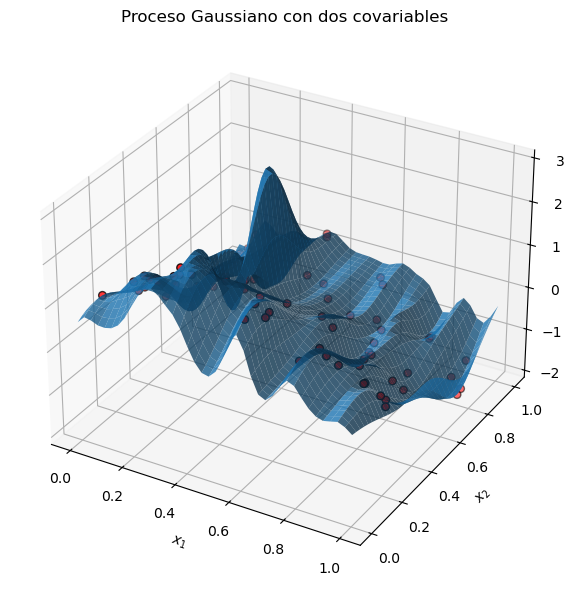

In [93]:
# 6. Visualización -------------------------------------------------------------
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (import necesario)

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')

# Superficie de la media posterior
ax.plot_surface(Xg1, Xg2, y_mean, alpha=0.8)

# Puntos observados
ax.scatter(X[:, 0], X[:, 1], y, s=30, color='red',edgecolor='k')

ax.set_xlabel(r'$x_1$')
ax.set_ylabel(r'$x_2$')
ax.set_zlabel(r'$y$')
ax.set_title('Proceso Gaussiano con dos covariables')
plt.tight_layout()
plt.show()


## Conexión entre Procesos Gaussianos y Kriging

Los Procesos Gaussianos y el Kriging geoestadístico son, matemáticamente, **el mismo modelo expresado con vocabulario distinto**. Esta equivalencia no es una coincidencia: el Kriging Ordinario fue desarrollado de forma independiente en la geoestadística (Matheron 1963, Krige 1951) antes de que la teoría de GPs fuera formalizada en el aprendizaje automático (Rasmussen & Williams 2006). Reconocer esta conexión permite transferir intuiciones y herramientas entre ambas disciplinas.

### Diccionario de equivalencias

| Concepto en GP | Concepto en Kriging | Descripción |
|:---|:---|:---|
| **Kernel** $k(\mathbf{x}, \mathbf{x}')$ | **Variograma** $\gamma(\mathbf{h})$ | Función que mide la similitud/diferencia entre dos ubicaciones según su distancia $\mathbf{h} = \mathbf{x} - \mathbf{x}'$ |
| **Función de covarianza** $C(\mathbf{h}) = k(\mathbf{x}, \mathbf{x}')$ | **Covariograma** $C(\mathbf{h}) = \sigma^2 - \gamma(\mathbf{h})$ | Relación: $C(\mathbf{h}) = \sigma^2 - \gamma(\mathbf{h})$ |
| **Length-scale** $l$ | **Rango** (range) $a$ | Distancia a la cual la correlación cae a ~0 |
| **Varianza de señal** $\sigma^2$ | **Sill** $\sigma^2$ | Varianza total del proceso |
| **Varianza de ruido** $\sigma_n^2$ | **Nugget** $\tau^2$ | Variabilidad a distancia cero (error de medición + microescala) |
| **Media posterior** $\mu^*$ | **Predicción Kriging** $\hat{z}(\mathbf{x}^*)$ | Valor esperado en ubicaciones no observadas |
| **Varianza posterior** $\sigma^{*2}$ | **Varianza Kriging** $\sigma_K^2(\mathbf{x}^*)$ | Incertidumbre de la predicción |

### Relación algebraica

Dado un conjunto de $n$ observaciones $\mathbf{y} = [y_1, \ldots, y_n]^T$ en ubicaciones $\mathbf{X} = [\mathbf{x}_1, \ldots, \mathbf{x}_n]^T$, la predicción en un nuevo punto $\mathbf{x}^*$ es idéntica en ambos formalismos:

$$\mu^*(\mathbf{x}^*) = \mathbf{k}_*^T (K + \sigma_n^2 I)^{-1} \mathbf{y}$$

$$\sigma^{*2}(\mathbf{x}^*) = k(\mathbf{x}^*, \mathbf{x}^*) - \mathbf{k}_*^T (K + \sigma_n^2 I)^{-1} \mathbf{k}_*$$

donde $K_{ij} = k(\mathbf{x}_i, \mathbf{x}_j)$ es la matriz de covarianza entre puntos de entrenamiento y $\mathbf{k}_* = [k(\mathbf{x}_1, \mathbf{x}^*), \ldots, k(\mathbf{x}_n, \mathbf{x}^*)]^T$ es el vector de covarianzas entre los datos y el punto de predicción.

El Kriging Ordinario añade la restricción de insesgadez ($\sum_i \lambda_i = 1$) mediante un multiplicador de Lagrange, equivalente a usar una media constante desconocida en el GP (lo que se llama *Kriging Ordinario* en geoestadística o *GP con media constante desconocida*).

### Correspondencia entre kernels y modelos de variograma

Los modelos de variograma geoestadísticos clásicos tienen su equivalente exacto en kernels de GP:

| Modelo de variograma | Kernel GP equivalente | Propiedad |
|:---|:---|:---|
| **Esférico** | Aproximado por Matérn $\nu = 1.5$ | Funciones una vez diferenciables |
| **Exponencial** | Matérn $\nu = 0.5$ (Ornstein-Uhlenbeck) | Funciones continuas pero no diferenciables |
| **Gaussiano** | RBF (Squared Exponential) | Funciones infinitamente diferenciables |
| **Matérn $\nu = 2.5$** | Matérn $\nu = 2.5$ | Funciones dos veces diferenciables |

**Nota práctica:** El kernel RBF (equivalente al variograma Gaussiano) produce predicciones muy suaves que a menudo son **demasiado suaves** para fenómenos geofísicos reales. Los kernels Matérn (especialmente $\nu = 1.5$ o $\nu = 2.5$) son generalmente más realistas para variables como precipitación, elevación o concentración de contaminantes.

### ¿Por qué usar GPs en lugar de Kriging?

La ventaja del framework GP sobre el Kriging clásico radica en:

1. **Estimación conjunta de hiperparámetros:** El GP optimiza el length-scale $l$, la varianza $\sigma^2$ y el nugget $\sigma_n^2$ simultáneamente maximizando la verosimilitud marginal logarítmica (*log marginal likelihood*), sin necesidad de ajustar el variograma experimental de forma visual.

2. **Incertidumbre calibrada:** La varianza posterior del GP es una medida probabilística rigurosa de la incertidumbre, directamente interpretable como un intervalo de credibilidad bayesiano.

3. **Extensibilidad:** Los kernels se pueden combinar (suma, producto) para capturar estructuras más complejas (periodicidad, tendencias, múltiples escalas), lo que en Kriging requeriría modelos de variograma no estándar.

4. **Integración con modelos de aprendizaje automático:** Los GPs se pueden combinar con redes neuronales profundas (*Deep Kernel Learning*) o usarse como capa de incertidumbre en modelos bayesianos complejos.

### Demostración de equivalencia

El siguiente fragmento compara la predicción de un GP con kernel exponencial cuadrado y un Kriging Ordinario con variograma Gaussiano para los mismos datos:

```python
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel
from pykrige.ok import OrdinaryKriging

# Datos de entrenamiento: 20 puntos en 1D
np.random.seed(42)
X_train = np.sort(np.random.uniform(0, 10, 20))
y_train = np.sin(X_train) + np.random.normal(0, 0.1, 20)
X_pred = np.linspace(0, 10, 200)

# --- GP con kernel RBF (equivalente al variograma Gaussiano) ---
kernel = RBF(length_scale=1.0) + WhiteKernel(noise_level=0.01)
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
gp.fit(X_train.reshape(-1, 1), y_train)
mu_gp, std_gp = gp.predict(X_pred.reshape(-1, 1), return_std=True)

# --- Kriging Ordinario con variograma Gaussiano ---
ok = OrdinaryKriging(X_train, np.zeros_like(X_train), y_train,
                     variogram_model='gaussian')
mu_kr, var_kr = ok.execute('grid', X_pred, np.array([0.0]))
mu_kr = mu_kr.squeeze()

# Las predicciones mu_gp y mu_kr deben ser casi idénticas
print(f"Max diferencia GP vs Kriging: {np.max(np.abs(mu_gp - mu_kr)):.6f}")
```

Si la diferencia máxima es menor que 1e-3, la equivalencia queda demostrada empíricamente. Las pequeñas diferencias se deben a la estimación de hiperparámetros: el GP los optimiza automáticamente, mientras que el Kriging requiere ajuste manual del variograma.

### El rol de las variables de entrada en el kernel: ¿coordenadas o características?

Un Proceso Gaussiano no "sabe" geografía por sí mismo — su comportamiento depende estrictamente de qué variables se indexan en el kernel:

**Enfoque espacial geográfico (Kriging tradicional):** si las entradas del kernel son únicamente coordenadas $\mathbf{x} = [X_{\text{este}}, Y_{\text{norte}}]$, el kernel calcula distancias euclidianas sobre el mapa físico. El suavizado significa que puntos geográficamente cercanos tendrán valores similares — esto es exactamente lo que hicimos en `14_Kriging` y en los ejemplos de esta sección.

**Enfoque en el espacio de características (Machine Learning / GPR):** si el kernel recibe variables ambientales o geotécnicas en vez de coordenadas (p. ej. $\mathbf{x} = [\text{Pendiente}, \text{Porosidad}]$), calcula distancias en un **hiperespacio de propiedades físicas**. Dos laderas separadas por 50 km geográficos estarán "juntas" para el kernel si tienen pendientes y porosidades casi idénticas. Aquí el suavizado es conceptual: garantiza que cambios leves en las propiedades del terreno produzcan cambios leves y coherentes en la predicción, en vez de saltos numéricos caóticos.

Esta distinción es clave en geociencias: un modelo de susceptibilidad a deslizamientos puede usar coordenadas (interpolación puramente espacial), variables geotécnicas (regresión en espacio de características), o ambas combinadas mediante kernels compuestos (suma o producto de kernels sobre distintos subconjuntos de variables).

### De la regresión a otros procesos: LGCP y GPC

El GP que hemos construido en este notebook modela una **variable continua** (regresión). Sin embargo, el mismo componente latente $Z(\mathbf{x}) \sim \mathcal{GP}(0, k(\mathbf{x}, \mathbf{x}'))$ puede combinarse con distintos filtros de observación para modelar otros tipos de datos:

| Modelo | Filtro sobre $Z(\mathbf{x})$ | ¿Qué mide? (ejemplo) |
|:---|:---|:---|
| **GPR (este notebook)** | Gaussiano $\mathcal{N}(0, \sigma_n^2)$ — suma lineal de error | Un valor continuo (elevación, temperatura). |
| **LGCP** (Proceso Cox Log-Gaussiano) | Poisson$(\exp(Z))$ — filtro de conteo | Conteo de eventos puntuales discretos (p. ej. cicatrices de deslizamientos por celda). |
| **GPC** (Clasificación) | Bernoulli(sigmoide($Z$)) — filtro de probabilidad binaria | Una condición binaria (ladera se deslizó [1] o no [0]). |

El **LGCP** es especialmente relevante en geociencias porque modela directamente la ocurrencia de eventos (sismos, deslizamientos, árboles) como un **proceso de Poisson doblemente estocástico**: la intensidad $\lambda(\mathbf{x}) = \exp(Z(\mathbf{x}))$ ya es aleatoria por el GP latente (azar del entorno), y sobre esa intensidad el conteo final de eventos añade una segunda capa de azar propia de la distribución de Poisson (azar del conteo). Esto lo distingue de un Proceso de Poisson no homogéneo clásico, donde $\lambda(\mathbf{x})$ está completamente determinada por variables predictoras conocidas sin incertidumbre residual:
$$\lambda(\mathbf{x}) = \exp(\beta_1 \cdot \text{Pendiente}(\mathbf{x}) + \beta_2 \cdot \text{Geología}(\mathbf{x}) + Z(\mathbf{x}))$$
donde el término $Z(\mathbf{x})$ es precisamente lo que distingue al LGCP: incluso conociendo las variables predictoras, la intensidad sigue siendo aleatoria por ese componente latente.

**Nota sobre modelos híbridos:** cuando se combina una tendencia (media) predictiva con un GP para modelar los residuos, la naturaleza del modelo de tendencia importa. Una tendencia **lineal** se complementa bien con el GP: al ser rígida, deja limpiamente los residuos no lineales al kernel. Una tendencia **no lineal compleja** (Random Forest, redes neuronales) **compite** con el GP: al ser un aproximador universal, puede absorber toda la variabilidad y dejar al GP sin estructura residual que modelar (pérdida de identificabilidad). La solución habitual es un enfoque **secuencial** (entrenar primero el modelo no lineal, y ajustar el GP solo sobre sus residuos) o usar la red como extractor de características para un GP posterior (*Deep Kernel Learning*).

## Actividades

1. **Efecto del kernel:** Implementa un Proceso Gaussiano con tres kernels distintos: (a) RBF (Radial Basis Function), (b) kernel exponencial, y (c) kernel Matérn (ν=1.5). Para los mismos datos de entrenamiento, grafica las predicciones y los intervalos de credibilidad al 95% de cada modelo. ¿Cómo difiere la suavidad de las predicciones entre kernels?

2. **Relación GP-Kriging:** El Kriging Ordinario puede verse como un caso especial de GP con un kernel determinado. Demuestra empíricamente esta equivalencia: ajusta un GP con kernel exponencial cuadrado y un Kriging Ordinario con variograma Gaussiano al mismo dataset de 20 puntos. Grafica las predicciones de ambos y verifica que son (aproximadamente) iguales.

3. **Hiperparámetros del kernel:** Para el kernel RBF ($k(x, x') = \sigma^2 e^{-\|x-x'\|^2 / 2l^2}$), varía el length-scale $l$ entre 0.1, 1 y 10. Para cada valor, grafica muestras del proceso previo (prior samples). ¿Cómo afecta $l$ a la suavidad espacial y a la longitud de correlación del proceso?

4. **GP con ruido:** Implementa un GP con término de ruido ($\sigma_n^2$) para un conjunto de 30 puntos con observaciones ruidosas. Varía $\sigma_n^2$ entre 0.01, 0.1 y 1.0. ¿Cómo cambia el comportamiento del modelo al pasar por los puntos de entrenamiento versus suavizarlos?

## Recursos adicionales

### Documentación oficial
- [GPyTorch — Gaussian Processes in PyTorch](https://gpytorch.ai/)
- [GPflow — Gaussian Processes in TensorFlow](https://gpflow.readthedocs.io/)
- [scikit-learn — Gaussian Process Regression](https://scikit-learn.org/stable/modules/gaussian_process.html)

### Lecturas recomendadas
- Rasmussen, C. E. & Williams, C. K. I. (2006). *Gaussian Processes for Machine Learning*. MIT Press. [Disponible online](http://www.gaussianprocess.org/gpml/)
- Cressie, N. & Wikle, C. K. (2011). *Statistics for Spatio-Temporal Data*. Wiley.
- Banerjee, S., Carlin, B. P., & Gelfand, A. E. (2015). *Hierarchical Modeling and Analysis for Spatial Data* (2nd ed.). CRC Press.
- Stein, M. L. (1999). *Interpolation of Spatial Data: Some Theory for Kriging*. Springer.

### Recursos interactivos
- [A Visual Exploration of Gaussian Processes — distill.pub](https://distill.pub/2019/visual-exploration-gaussian-processes/)
- [GP Summer School — Material y videos](http://gpss.cc/gpss23/)
- [Gaussian Processes for Machine Learning — Tutorial interactivo](http://www.gaussianprocess.org/)